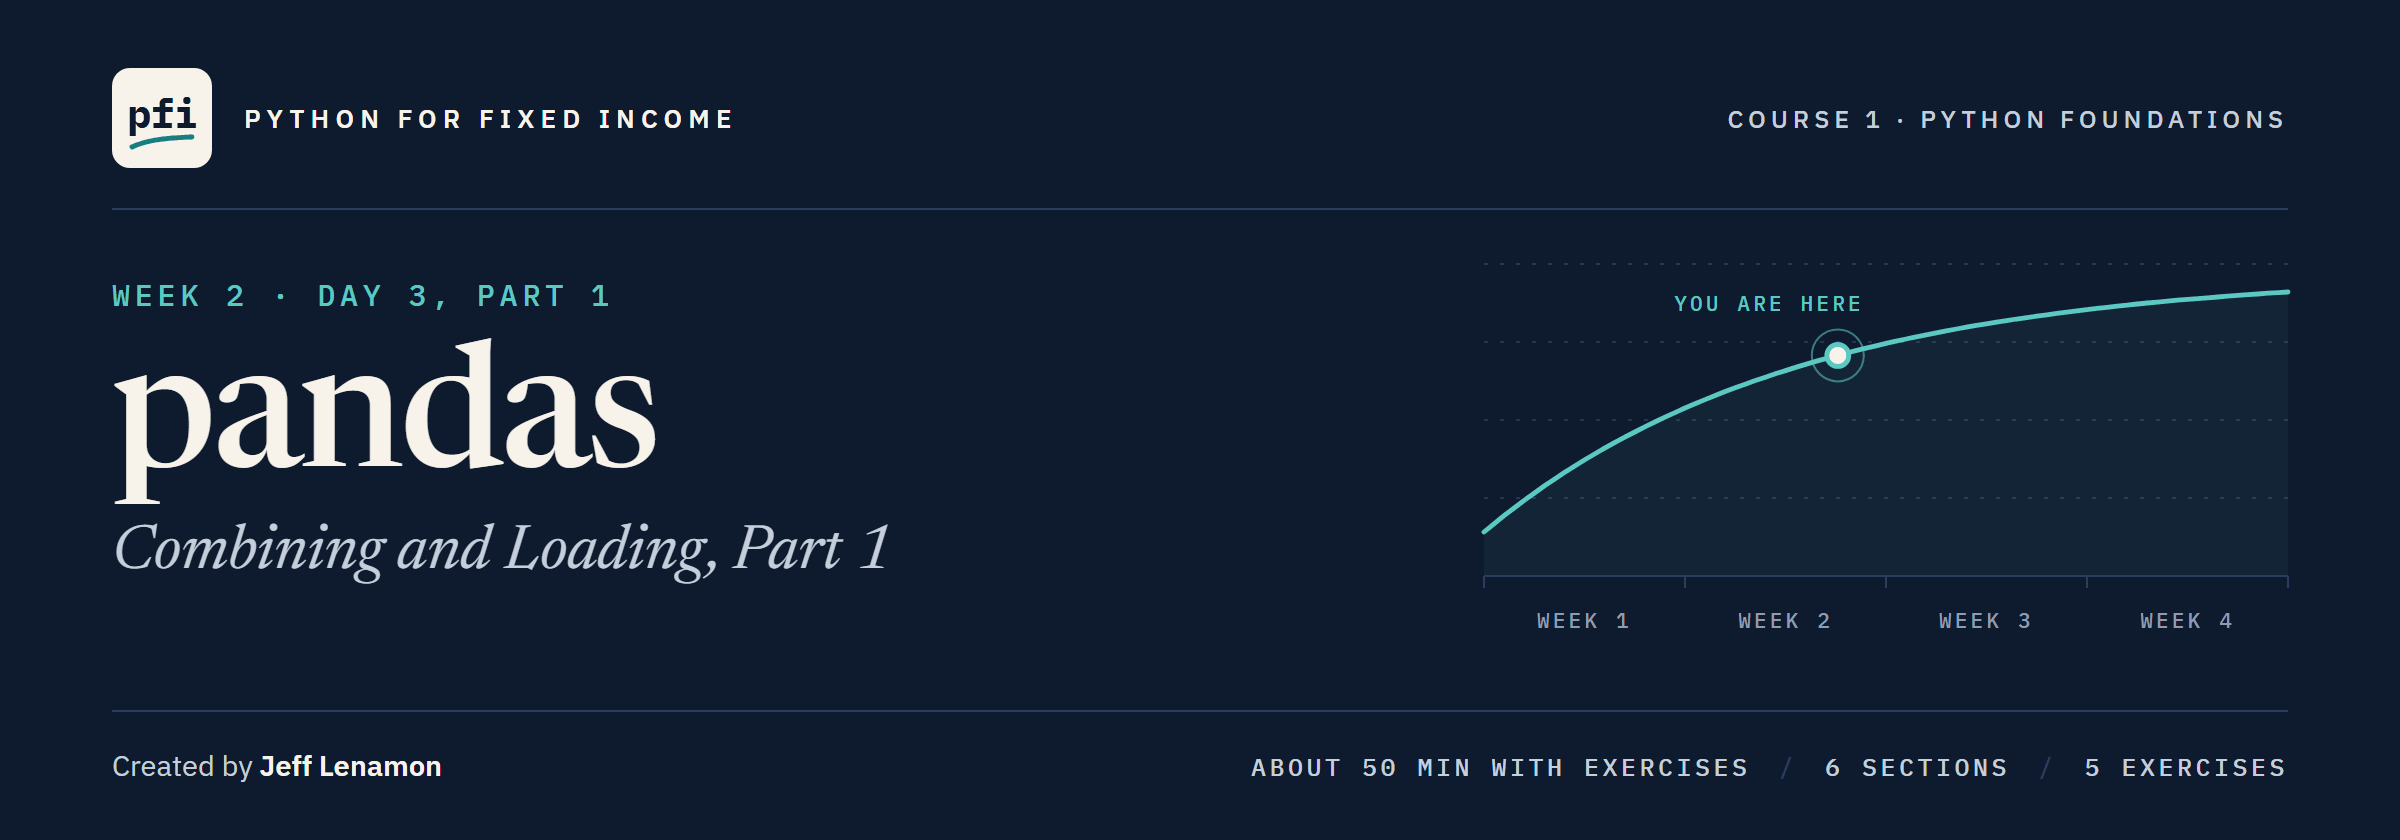

# pandas: Combining and Loading, Part 1

Week 2, Day 3, Part 1. Joining the desk's tables together, stacking them, and summarizing by group.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day3/08_pandas_combining_and_loading.ipynb)

## The Desk Lead's Twelfth Note

> Today's data comes from three systems: positions, issuer details, and the rating scale. Put a name, a sector, and a rating on every position, and show me none was lost or doubled. Which benchmark bonds do we hold, and what weight do they carry? Then the book by sector, in money, beside the benchmark.

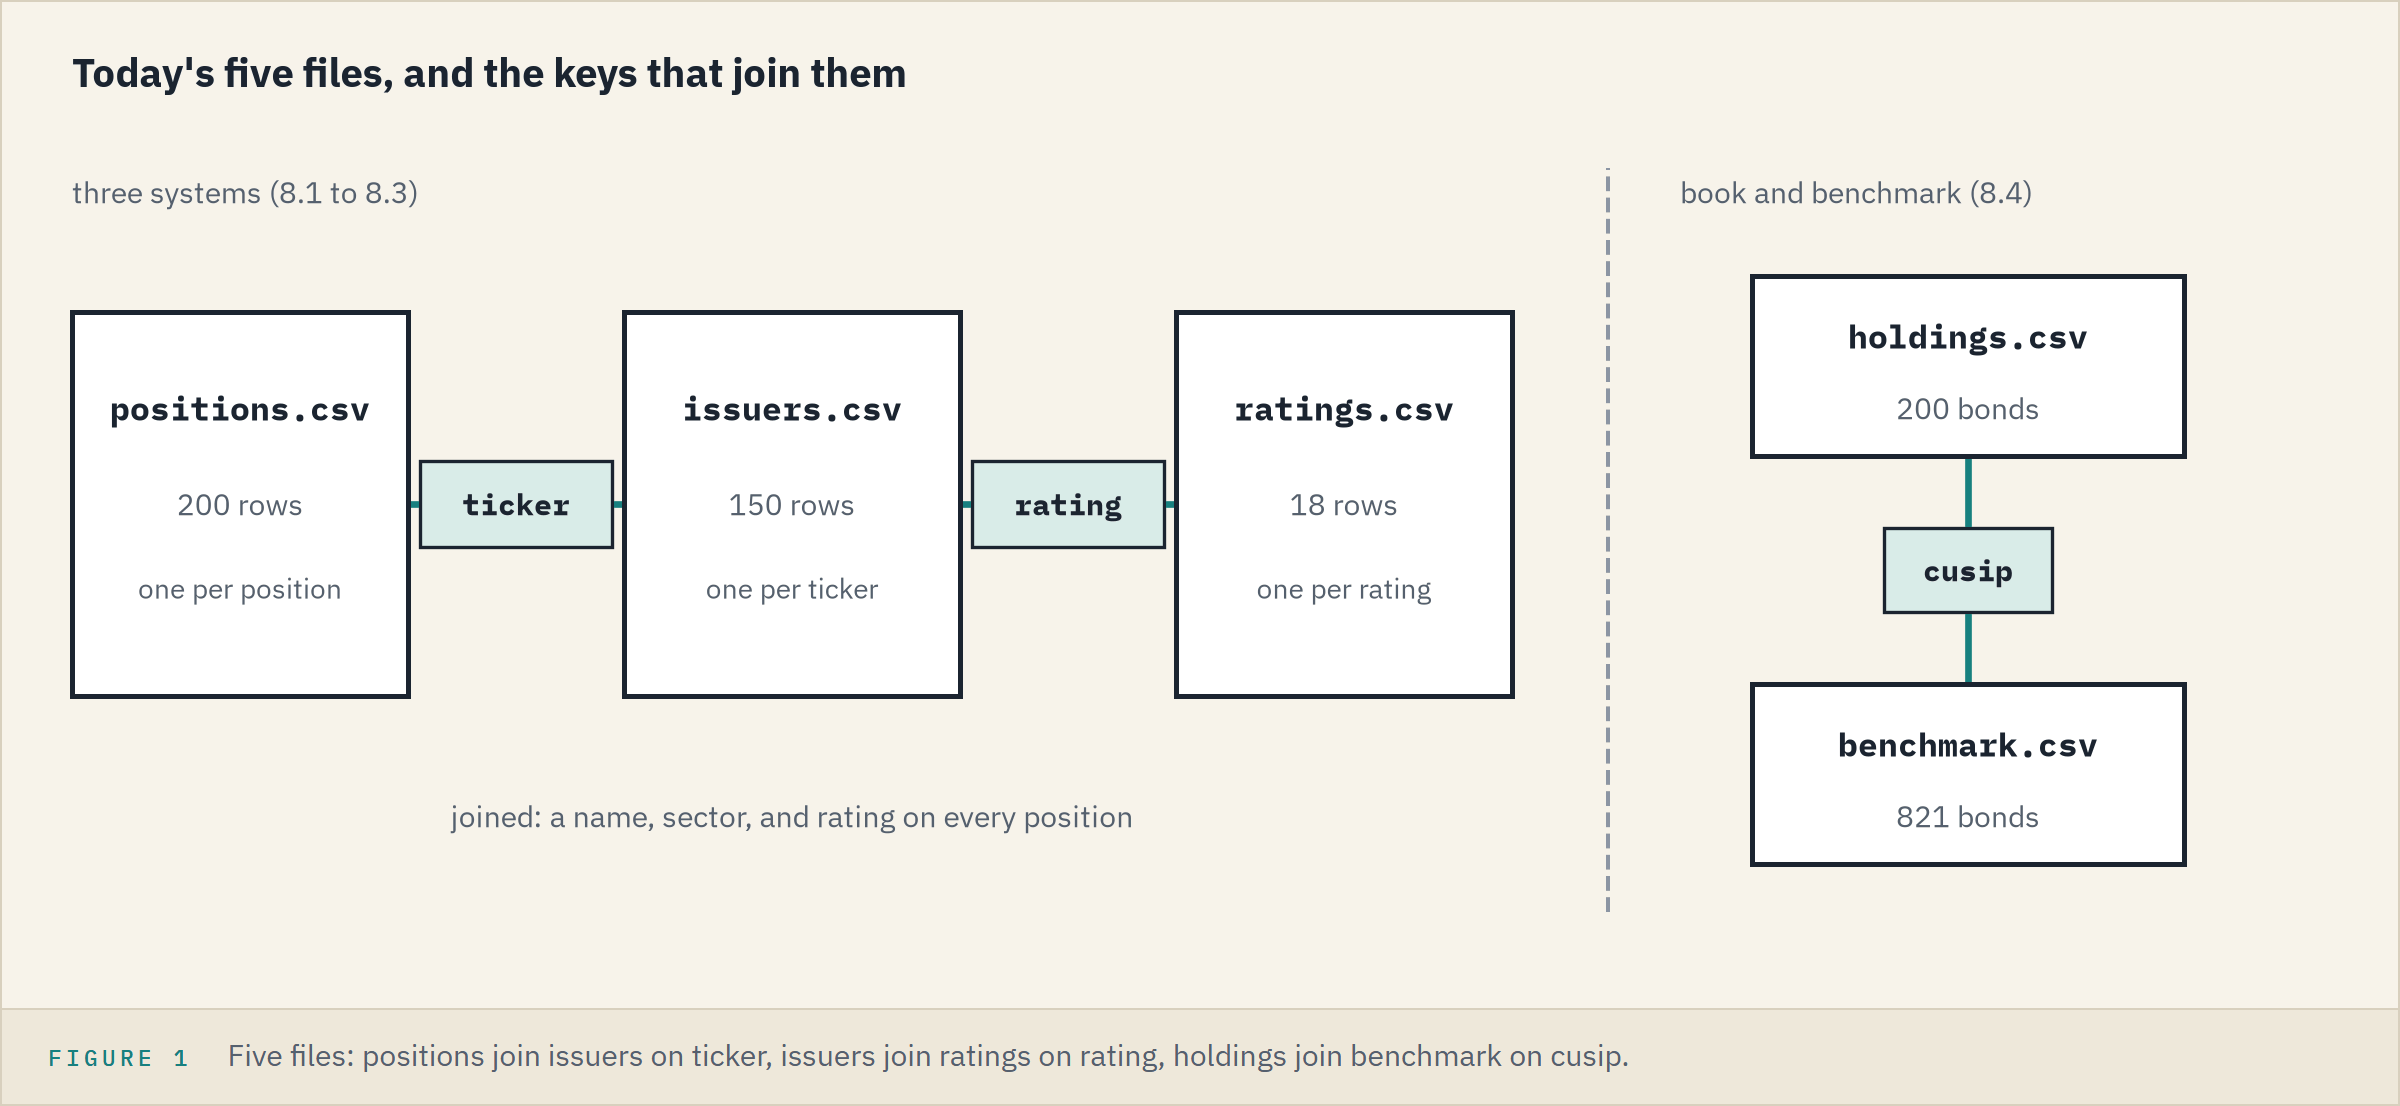

The issuers are invented.

**Three pieces, joined by two keys: load them first.**

## Your Route Through Day 3, Part 1

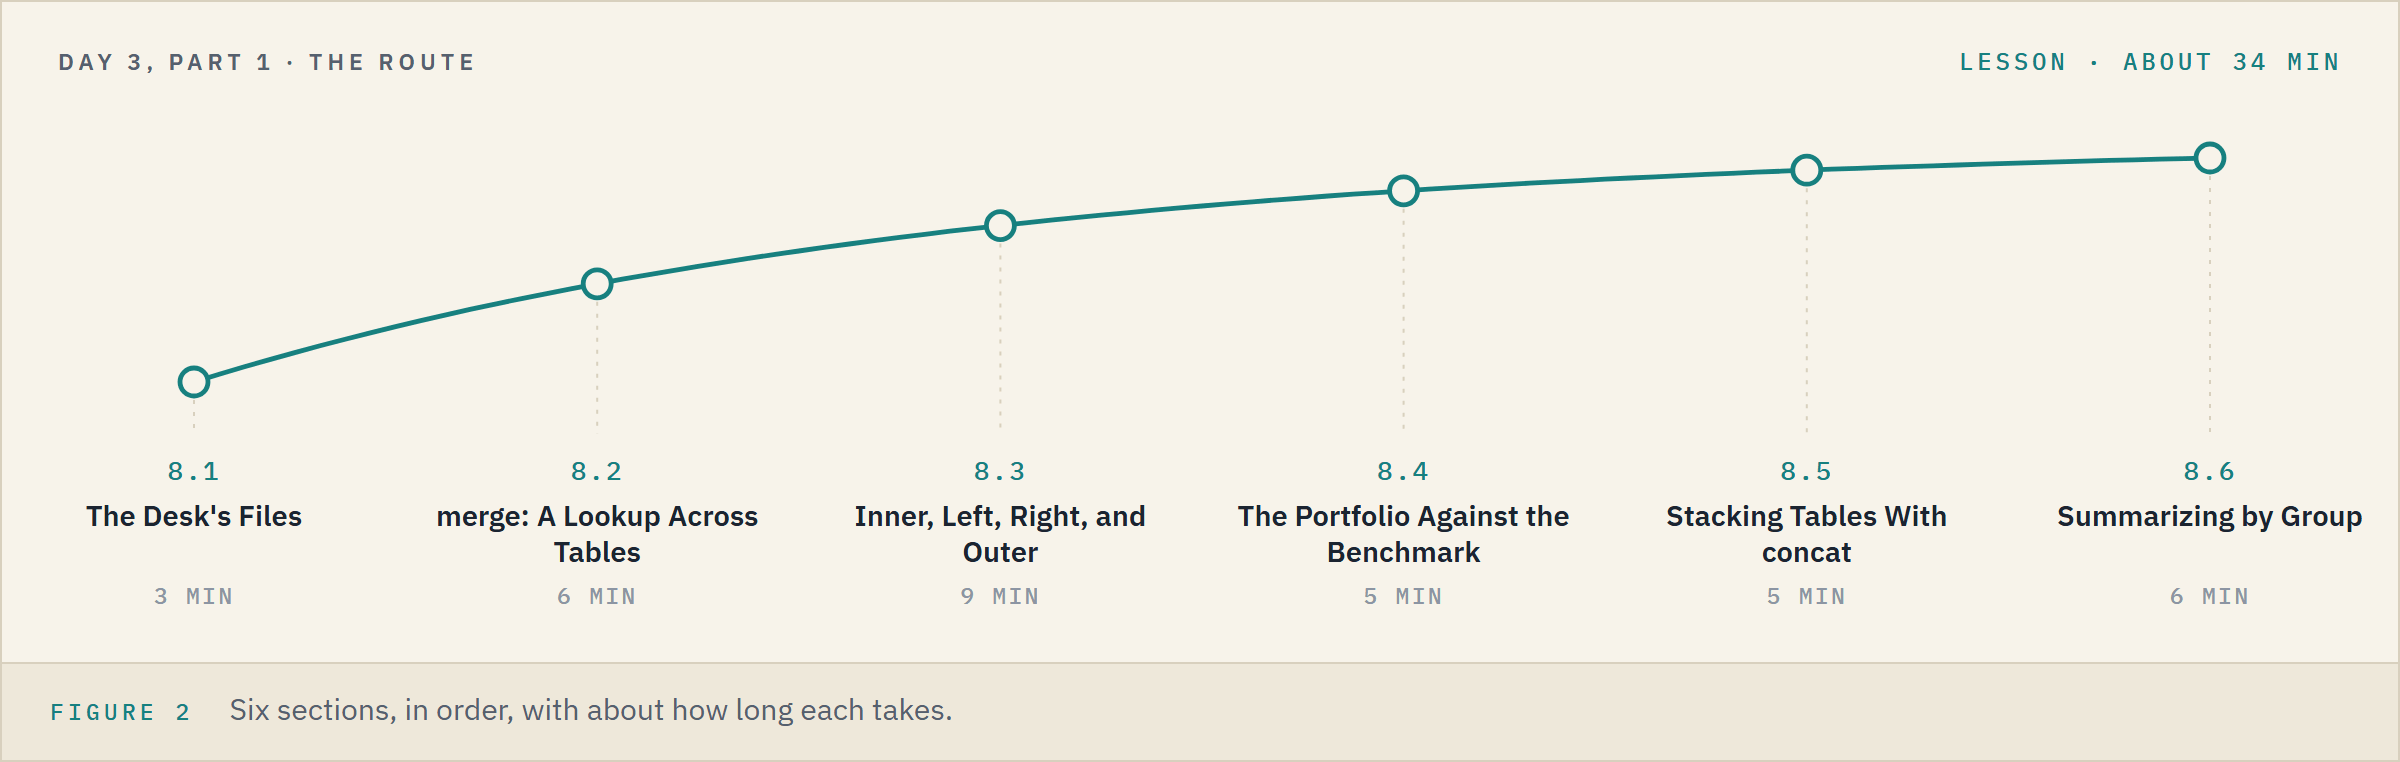

**Time.** About 34 minutes for the lesson, then about 15 for the five exercises.

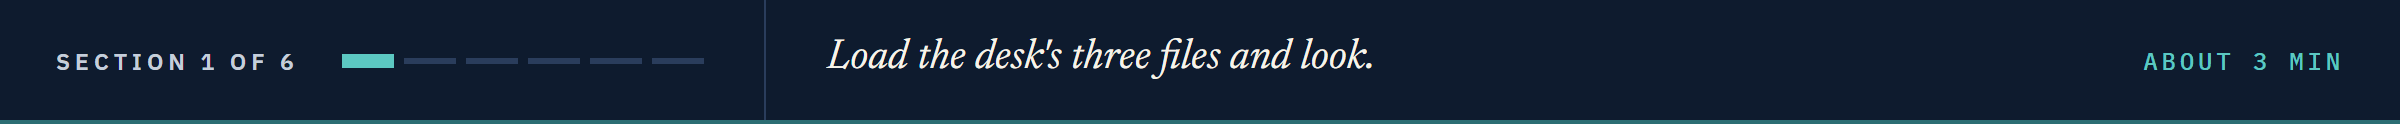

## 8.1 The Desk's Files

### The Positions File

Q. Load the positions file. How large is it, and what are its first rows?

In [1]:
import os

import pandas as pd

# the repo's data folder on your machine; in Colab, GitHub (7.3)
if os.path.exists('../../../data/positions.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
# + joins two pieces of text, as in week 1: the folder, then the file name
positions = pd.read_csv(data_folder + 'positions.csv')
print(positions.shape)
positions.head(3)

(200, 6)


,cusip,ticker,coupon,maturity,price,par_held
0,99080CAE8,BEZE,7.000,2032-06-18,106.727,5000000
1,99049XAE2,BEZH,8.125,2029-04-17,97.556,250000
2,99039NAC0,BEZL,5.125,2030-06-03,98.730,1500000


The lean file a position system sends: the issuer is only a ticker.

### The Issuers: One Row per Ticker

Q. Load the issuer file. Is any ticker listed twice?

In [2]:
# the issuer file, from the same folder
issuers = pd.read_csv(data_folder + 'issuers.csv')
# nunique() counts the different values (7.6)
print(issuers.shape, issuers['ticker'].nunique())
issuers.head(3)

(150, 5) 150


,ticker,issuer,sector,country,rating
0,QVNE,Quorvane Energy,Energy,US,BBB
1,DNMR,Dunmarrow Rail,Transportation,US,BB+
2,PLWK,Pellwick Paper,Materials,US,A-


### The Rating Scale

Q. Load the rating scale and show its first eleven rows.

In [3]:
# the rating scale: one row per rating
ratings = pd.read_csv(data_folder + 'ratings.csv')
print(ratings.shape)
ratings.head(11)

(18, 4)


,rating,score,bucket,grade
0,AAA,1,AAA,Investment Grade
1,AA+,2,AA,Investment Grade
2,AA,3,AA,Investment Grade
3,AA-,4,AA,Investment Grade
4,A+,5,A,Investment Grade
5,A,6,A,Investment Grade
6,A-,7,A,Investment Grade
7,BBB+,8,BBB,Investment Grade
8,BBB,9,BBB,Investment Grade
9,BBB-,10,BBB,Investment Grade


Each issuer is listed once; the first three are week 1's QVNE, DNMR, and PLWK.

<table align="left">
<tr><th align="left">Column</th><th align="left">Holds</th></tr>
<tr><td align="left"><code>score</code></td><td align="left">week 1's number: 1 for AAA, one more per notch down</td></tr>
<tr><td align="left"><code>bucket</code></td><td align="left">the notches grouped: AA+, AA, and AA- are all AA</td></tr>
<tr><td align="left"><code>grade</code></td><td align="left">Investment Grade down to BBB-, score 10; High Yield from BB+, score 11</td></tr>
</table>
<br clear="left">

### Many Positions, One Issuer

Q. How many different tickers does the desk hold?

In [4]:
# 200 positions: how many issuers?
print('Tickers held:', positions['ticker'].nunique())

Tickers held: 115


**Many rows on one side, one on the other: the shape of a lookup.**

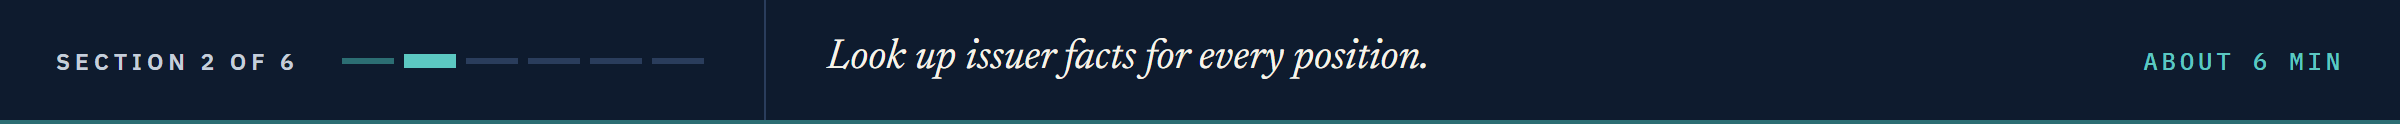

## 8.2 `merge`: A Lookup Across Tables

### One `merge`, Three Columns

In Excel this is a `VLOOKUP` on the ticker, filled down 200 rows, once for each column wanted.

Q. Put the issuer's name, sector, and rating on every position. How many rows come out?

In [5]:
# the key to match on, and the three columns to bring in
issuer_details = issuers[['ticker', 'issuer', 'sector', 'rating']]
# pd.merge(left, right, on=): each left row meets the right row with the same ticker
named = pd.merge(positions, issuer_details, on='ticker')
print(positions.shape, issuer_details.shape, named.shape)
named.head(3)

(200, 6) (150, 4) (200, 9)


,cusip,ticker,coupon,maturity,price,par_held,issuer,sector,rating
0,99080CAE8,BEZE,7.000,2032-06-18,106.727,5000000,Bezane Finance,Financials,BBB-
1,99049XAE2,BEZH,8.125,2029-04-17,97.556,250000,Bezamyth Machinery,Industrials,B
2,99039NAC0,BEZL,5.125,2030-06-03,98.730,1500000,Bezoquil Freight,Transportation,BB


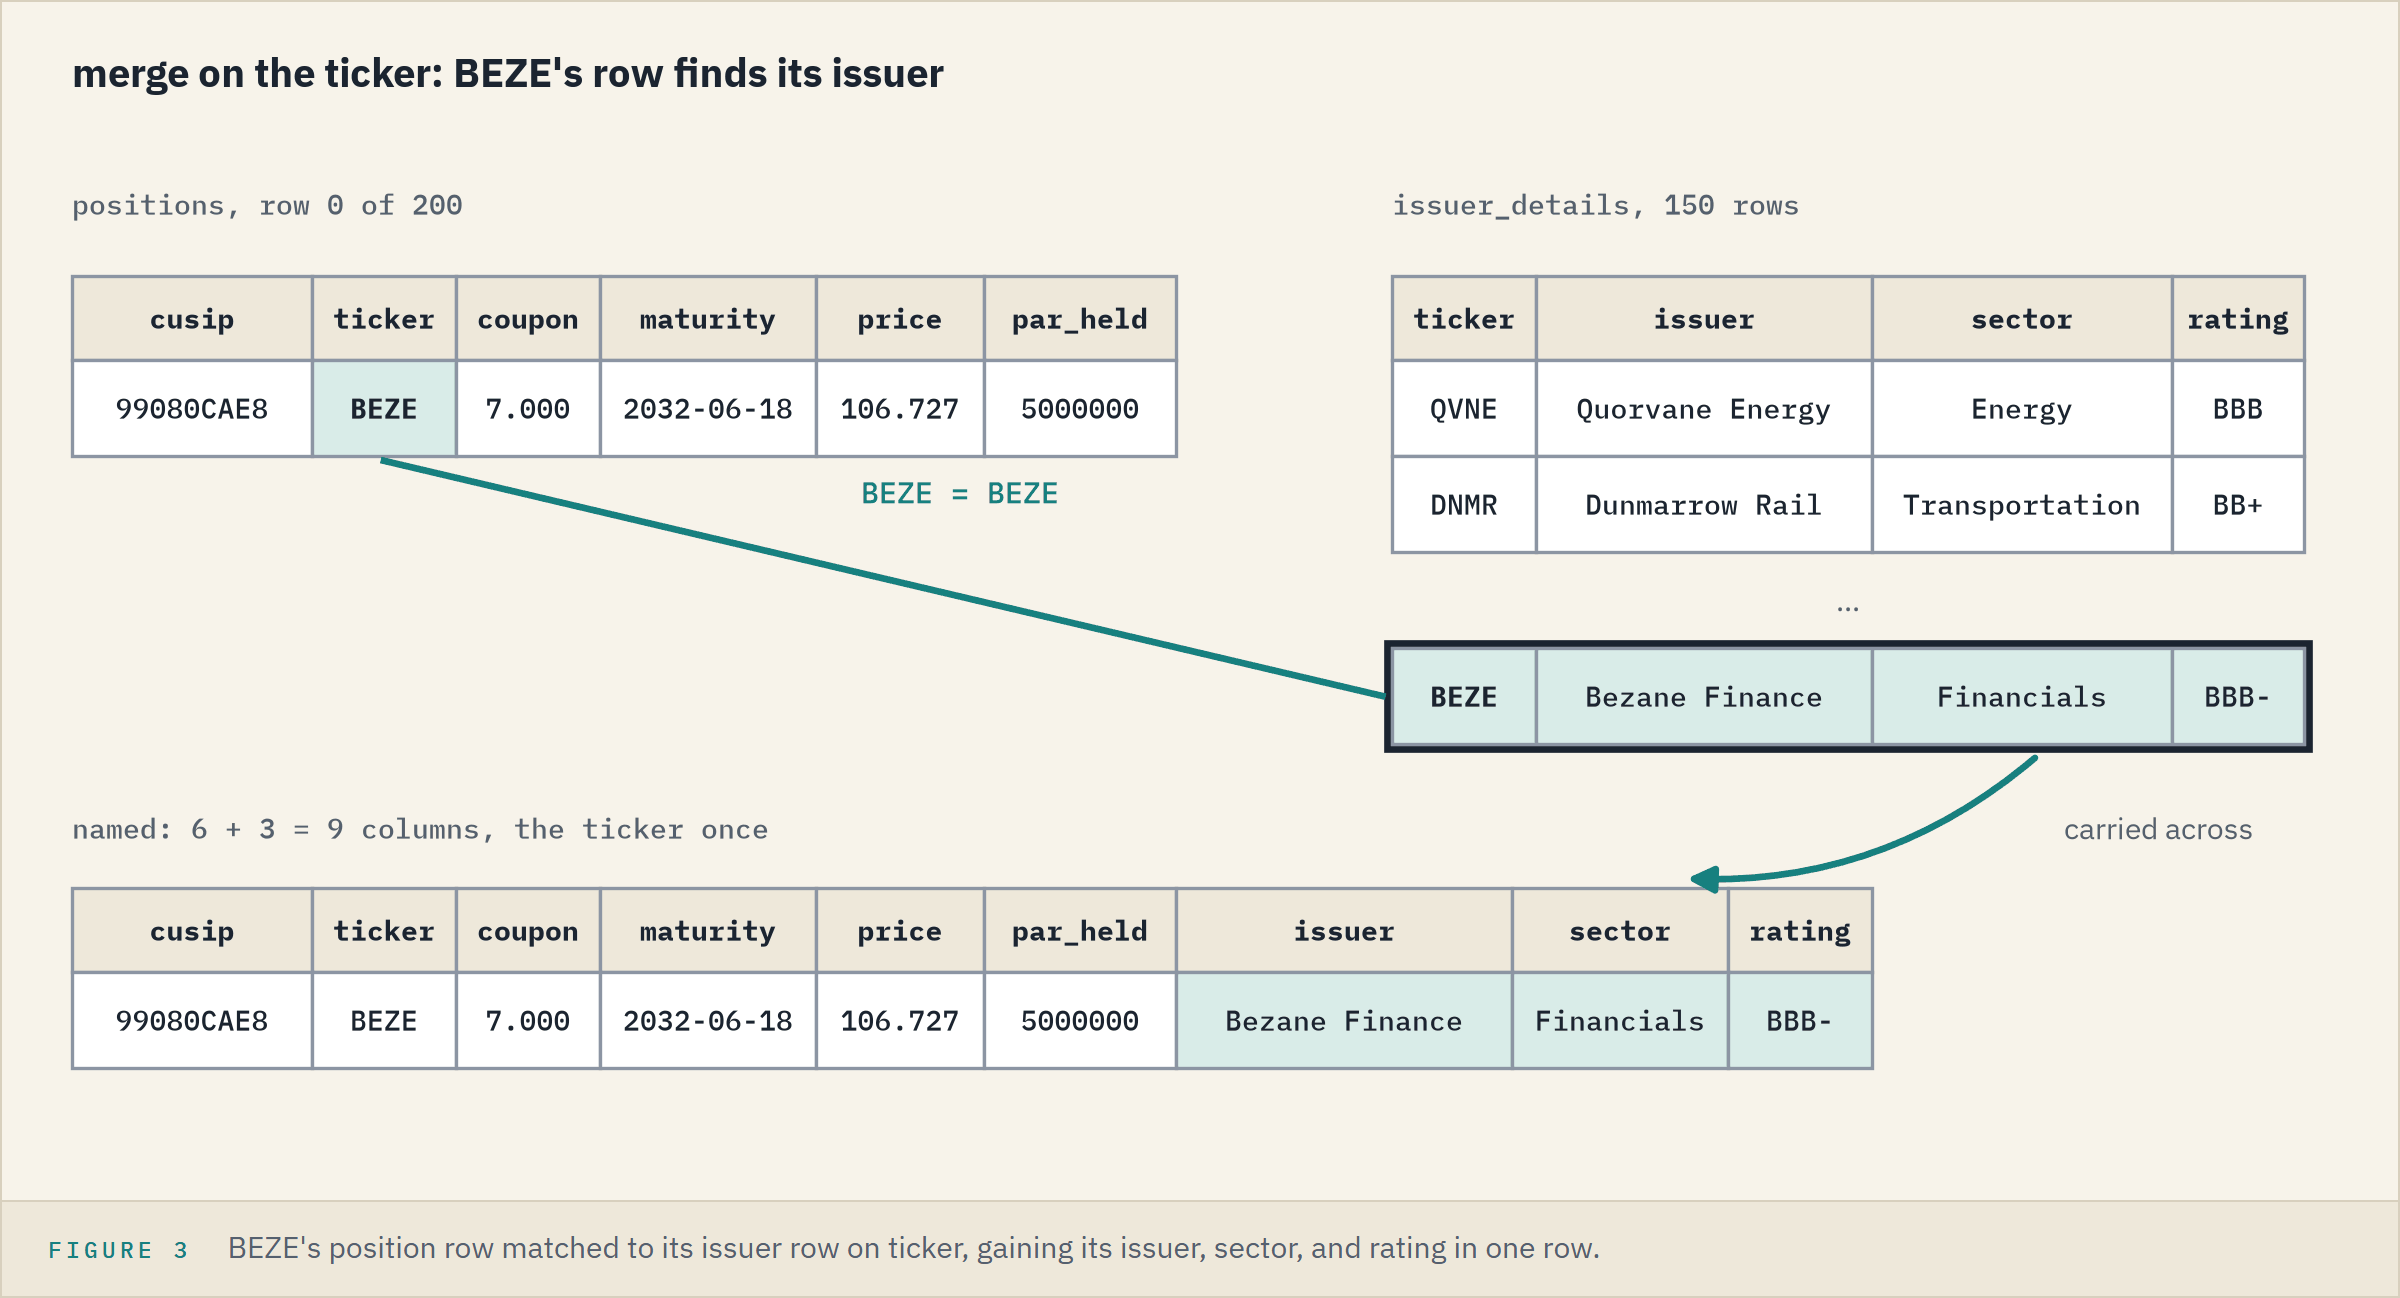

`on=` names the column to match on: the **key**.

**200 in, 200 out, and three columns more.**

### The Rating Scale, Directly

**Predict 1**

Q. The rating scale is keyed on the rating. What does `pd.merge(positions, ratings, on='rating')` give?

A) 200 rows, with the score, bucket, and grade added.
B) Fewer than 200 rows: some ratings find no match.
C) An error.

In [6]:
# the positions straight to the rating scale, on the rating
pd.merge(positions, ratings, on='rating')

KeyError: 'rating'

C: the last line names the key, and `positions` has no `rating` column.
The rating came with the issuer details, so the table to join is `named`.
After a `KeyError`, print both tables' `columns` and compare.

**The key must be in both tables under one name.**

### A Key With Two Names

**Predict 2**

Q. Another issuer file calls its key `issuer_ticker`. `on='ticker'` gave nine columns, the key once. How many does `left_on='ticker', right_on='issuer_ticker'` give?

A) Nine.
B) Ten.

In [7]:
# rename() as in 7.9: here the issuers call their key issuer_ticker
other_names = issuer_details.rename(columns={'ticker': 'issuer_ticker'})
# left_on= names the key in the left table, right_on= in the right
different_keys = pd.merge(positions, other_names, left_on='ticker', right_on='issuer_ticker')
print(different_keys.shape)

(200, 10)


B: both keys stay, each under its own name.

### Score and Grade

Q. Add each position's rating score and grade.

In [8]:
# a second lookup: named now has the rating, the rating scale has the rest
rated = pd.merge(named, ratings[['rating', 'score', 'grade']], on='rating')
print(rated.shape)
rated[['ticker', 'issuer', 'rating', 'score', 'grade']].head(3)

(200, 11)


,ticker,issuer,rating,score,grade
0,BEZE,Bezane Finance,BBB-,10,Investment Grade
1,BEZH,Bezamyth Machinery,B,15,High Yield
2,BEZL,Bezoquil Freight,BB,12,High Yield


### Credit Order, Then Grade

The last notebook's text sort put AAA seventh.

Q. List the desk's ratings in credit order, then count each grade.

In [9]:
# sort by the number, then each rating once, as a list (7.6)
print(rated.sort_values('score')['rating'].unique().tolist())

['AAA', 'AA+', 'AA', 'AA-', 'A+', 'A', 'A-', 'BBB+', 'BBB', 'BBB-', 'BB+', 'BB', 'BB-', 'B+', 'B', 'B-', 'CCC+', 'CCC']


In [10]:
# value_counts() as in 7.6
rated['grade'].value_counts()

grade
Investment Grade    128
High Yield           72
Name: count, dtype: int64

A number sorts the way a rating should.

**Excel side by side.** Ticker in column B of the positions sheet; on the `issuers` sheet, ticker in A, sector in C:

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Bring in the sector</td><td align="left"><code>pd.merge(positions, issuers[['ticker', 'sector']], on='ticker')</code></td><td align="left"><code>=VLOOKUP(B2, issuers!A:C, 3, FALSE)</code> filled down</td></tr>
<tr><td align="left">Without counting columns</td><td align="left">the same line</td><td align="left"><code>=XLOOKUP(B2, issuers!A:A, issuers!C:C)</code> in Excel 2021 or later and Microsoft 365; <code>INDEX</code> and <code>MATCH</code> in any version</td></tr>
</table>
<br clear="left">

**Three tables answered what one file could not: 128 investment grade, 72 high yield.**

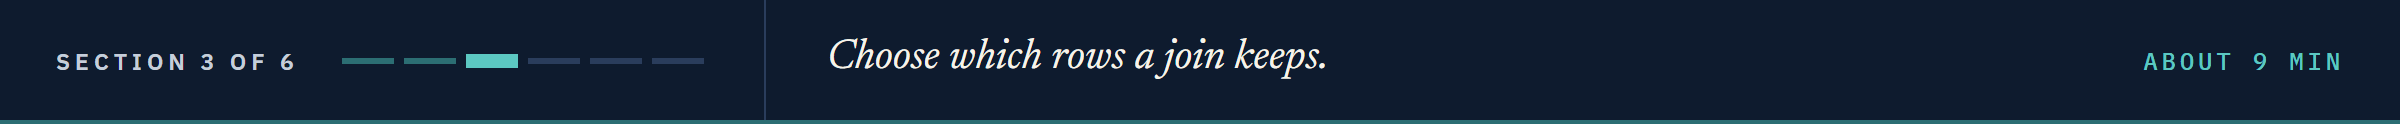

## 8.3 Inner, Left, Right, and Outer

### Two Small Tables

Q. Make week 1's four bonds a table, and a sector table that does not quite match it.

In [11]:
# the desk's four bonds
desk_small = pd.DataFrame({'ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
                           'face': [1500000, 500000, 750000, 250000]})
# no row for HLVF, and a row for THAR, which the desk does not hold
sector_small = pd.DataFrame({'ticker': ['QVNE', 'DNMR', 'PLWK', 'THAR'],
                             'sector': ['Energy', 'Transportation', 'Materials',
                                        'Materials']})
print(desk_small)
print(sector_small)

  ticker     face
0   QVNE  1500000
1   DNMR   500000
2   PLWK   750000
3   HLVF   250000
  ticker          sector
0   QVNE          Energy
1   DNMR  Transportation
2   PLWK       Materials
3   THAR       Materials


### Merge Without Saying How

**Predict 3**

Q. How many rows does `pd.merge(desk_small, sector_small, on='ticker')` return?

A) Five: every ticker from both tables.
B) Four: every bond the desk holds.
C) Three: the tickers in both tables.

In [12]:
# no how= given
pd.merge(desk_small, sector_small, on='ticker')

,ticker,face,sector
0,QVNE,1500000,Energy
1,DNMR,500000,Transportation
2,PLWK,750000,Materials


C: `how='inner'` is the default, and keeps a row only when its key is in both tables.
HLVF's 250,000 of face left the table.

**An inner merge drops what does not match, with no warning.**

### Keep Every Position

Q. Keep every row of the desk's table, matched or not. Which bonds found no sector?

In [13]:
# how='left' keeps every row of the left table
left_join = pd.merge(desk_small, sector_small, on='ticker', how='left')
left_join

,ticker,face,sector
0,QVNE,1500000,Energy
1,DNMR,500000,Transportation
2,PLWK,750000,Materials
3,HLVF,250000,NaN


In [14]:
# isna(): True where a value is missing
no_sector = left_join['sector'].isna()
print('No sector:', no_sector.sum())
left_join[no_sector]

No sector: 1


,ticker,face,sector
3,HLVF,250000,NaN


A left merge is the closest to `VLOOKUP`: every row of your sheet stays.
`isna()` is a mask, so it filters and counts as in 7.7; `notna()` is its opposite.

### Keep Theirs, Then Keep Everything

Q. Keep every row of the sector table. Then keep every row of both, and show where each was found.

In [15]:
# how='right' keeps every row of the right table
pd.merge(desk_small, sector_small, on='ticker', how='right')

,ticker,face,sector
0,QVNE,1500000.0,Energy
1,DNMR,500000.0,Transportation
2,PLWK,750000.0,Materials
3,THAR,NaN,Materials


In [16]:
# how='outer' keeps every key; indicator=True adds _merge, where each row was found
pd.merge(desk_small, sector_small, on='ticker', how='outer', indicator=True)

,ticker,face,sector,_merge
0,DNMR,500000.0,Transportation,both
1,HLVF,250000.0,NaN,left_only
2,PLWK,750000.0,Materials,both
3,QVNE,1500000.0,Energy,both
4,THAR,NaN,Materials,right_only


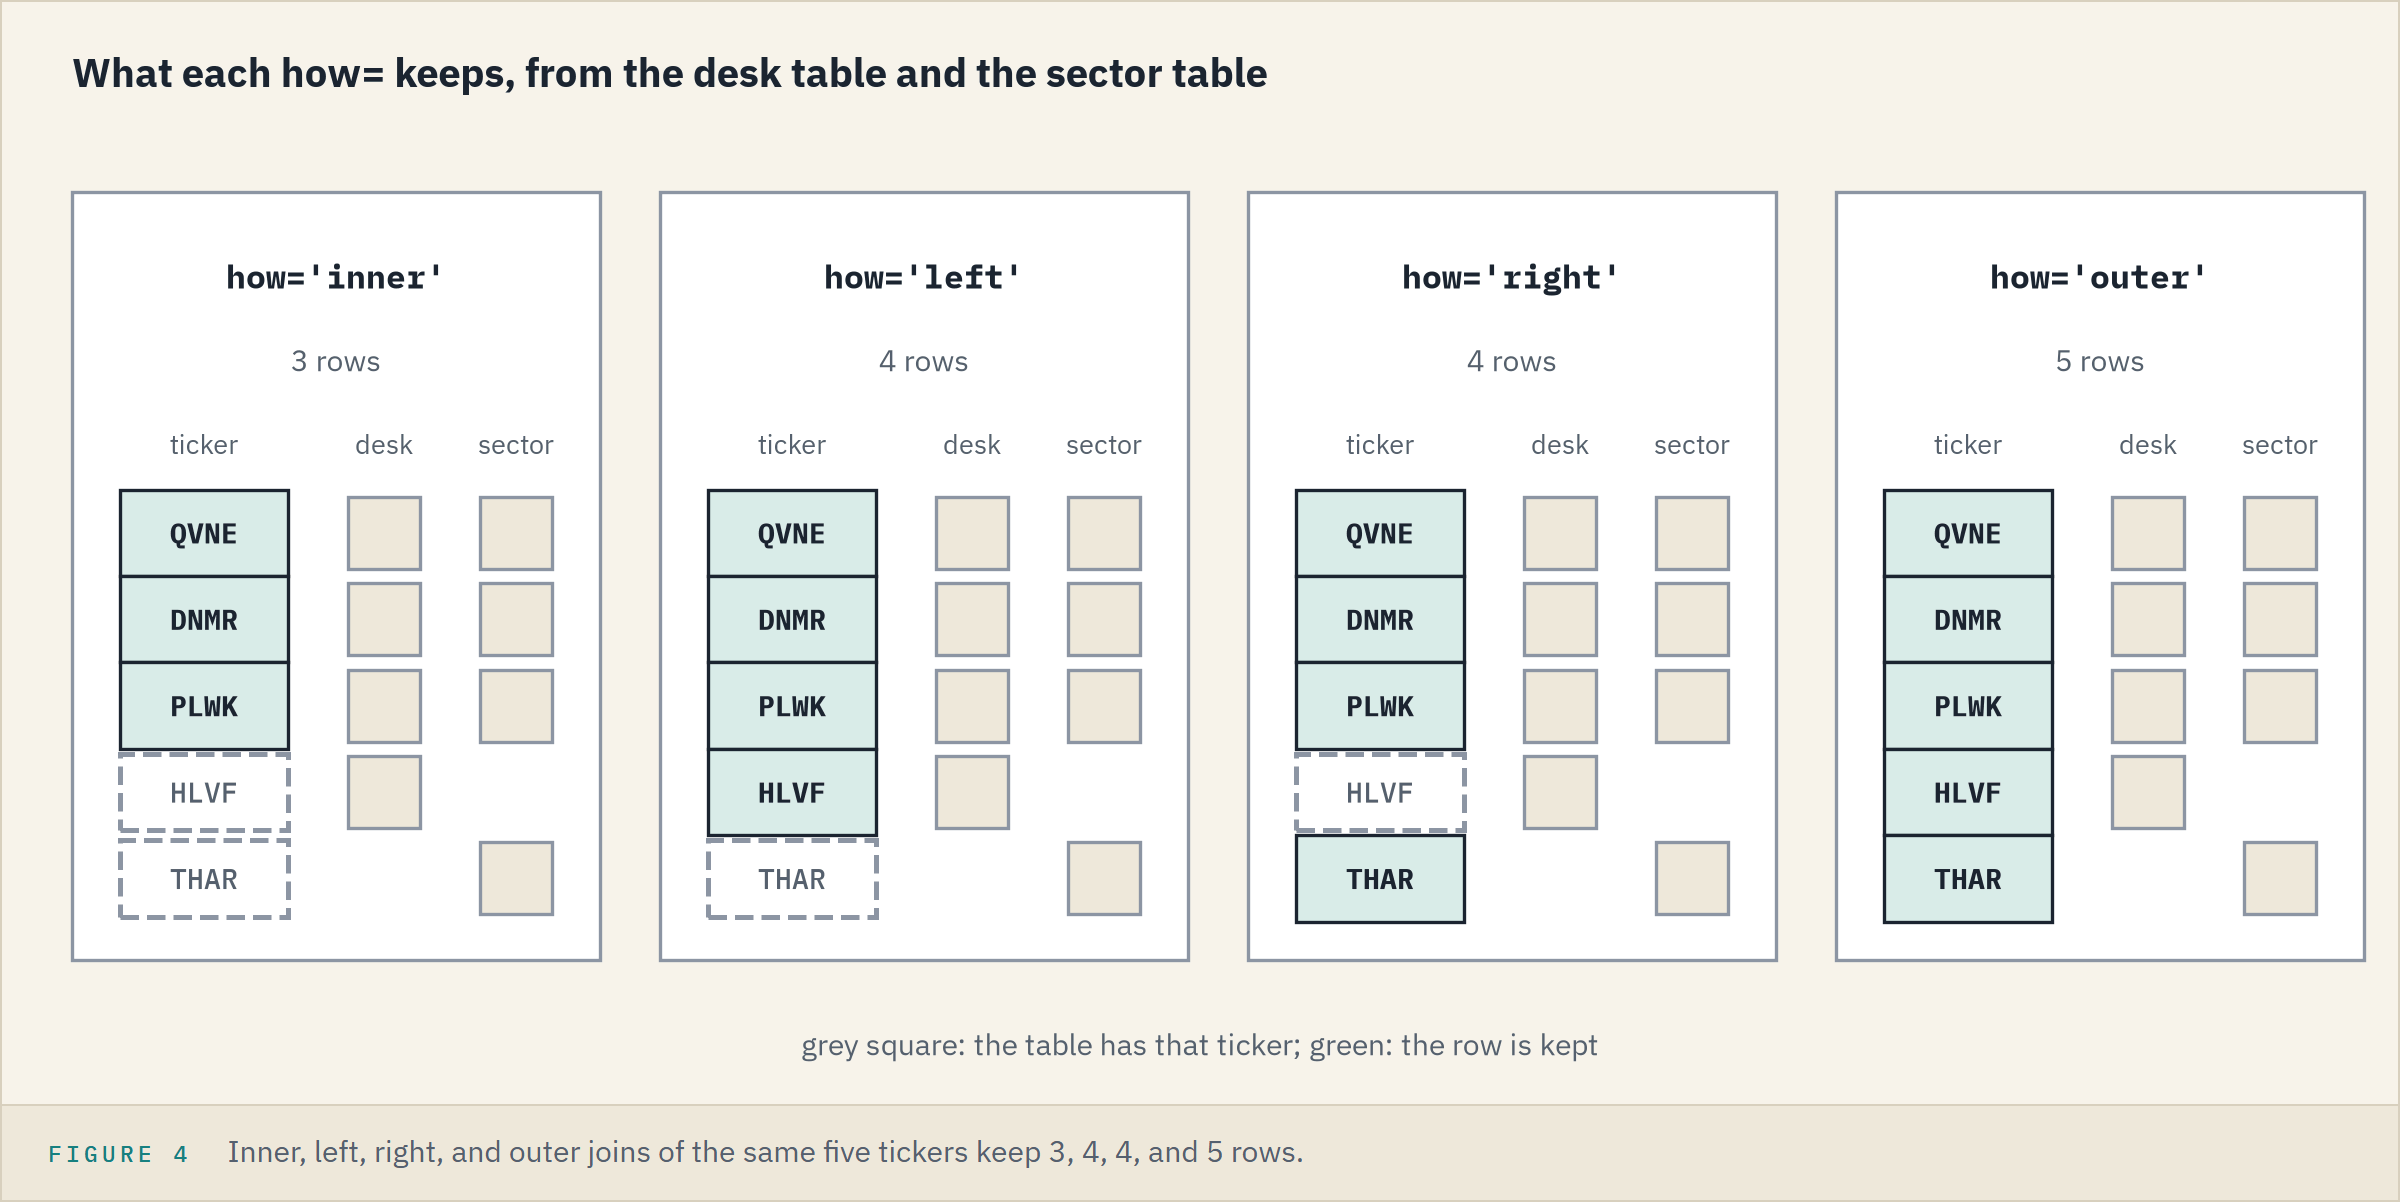

THAR has no face, so `face` turns `float64` to hold the `NaN` (Day 5).
Outer sorts the rows by ticker; `_merge` reads `both`, `left_only`, or `right_only`, the fastest view of what did not match.
`inner` keeps what both share, `left` all of yours, `right` all of theirs, `outer` everything.

**For details on a list of positions, use `left`.**

### A Key Listed Twice

**Predict 4**

Q. A sector table lists QVNE twice. The desk's face adds to 3,000,000. What does it add to after a left merge?

A) 3,000,000: a left merge keeps the desk's four rows.
B) 4,500,000: QVNE's 1,500,000 counted twice.
C) An error: a key is listed twice.

In [17]:
# QVNE twice in this lookup table
sector_twice = pd.DataFrame({'ticker': ['QVNE', 'QVNE', 'DNMR', 'PLWK', 'HLVF'],
                             'sector': ['Energy', 'Energy', 'Transportation', 'Materials',
                                        'Consumer']})
doubled = pd.merge(desk_small, sector_twice, on='ticker', how='left')
print(doubled)
print('Face before:', desk_small['face'].sum(), 'after:', doubled['face'].sum())

  ticker     face          sector
0   QVNE  1500000          Energy
1   QVNE  1500000          Energy
2   DNMR   500000  Transportation
3   PLWK   750000       Materials
4   HLVF   250000        Consumer
Face before: 3000000 after: 4500000


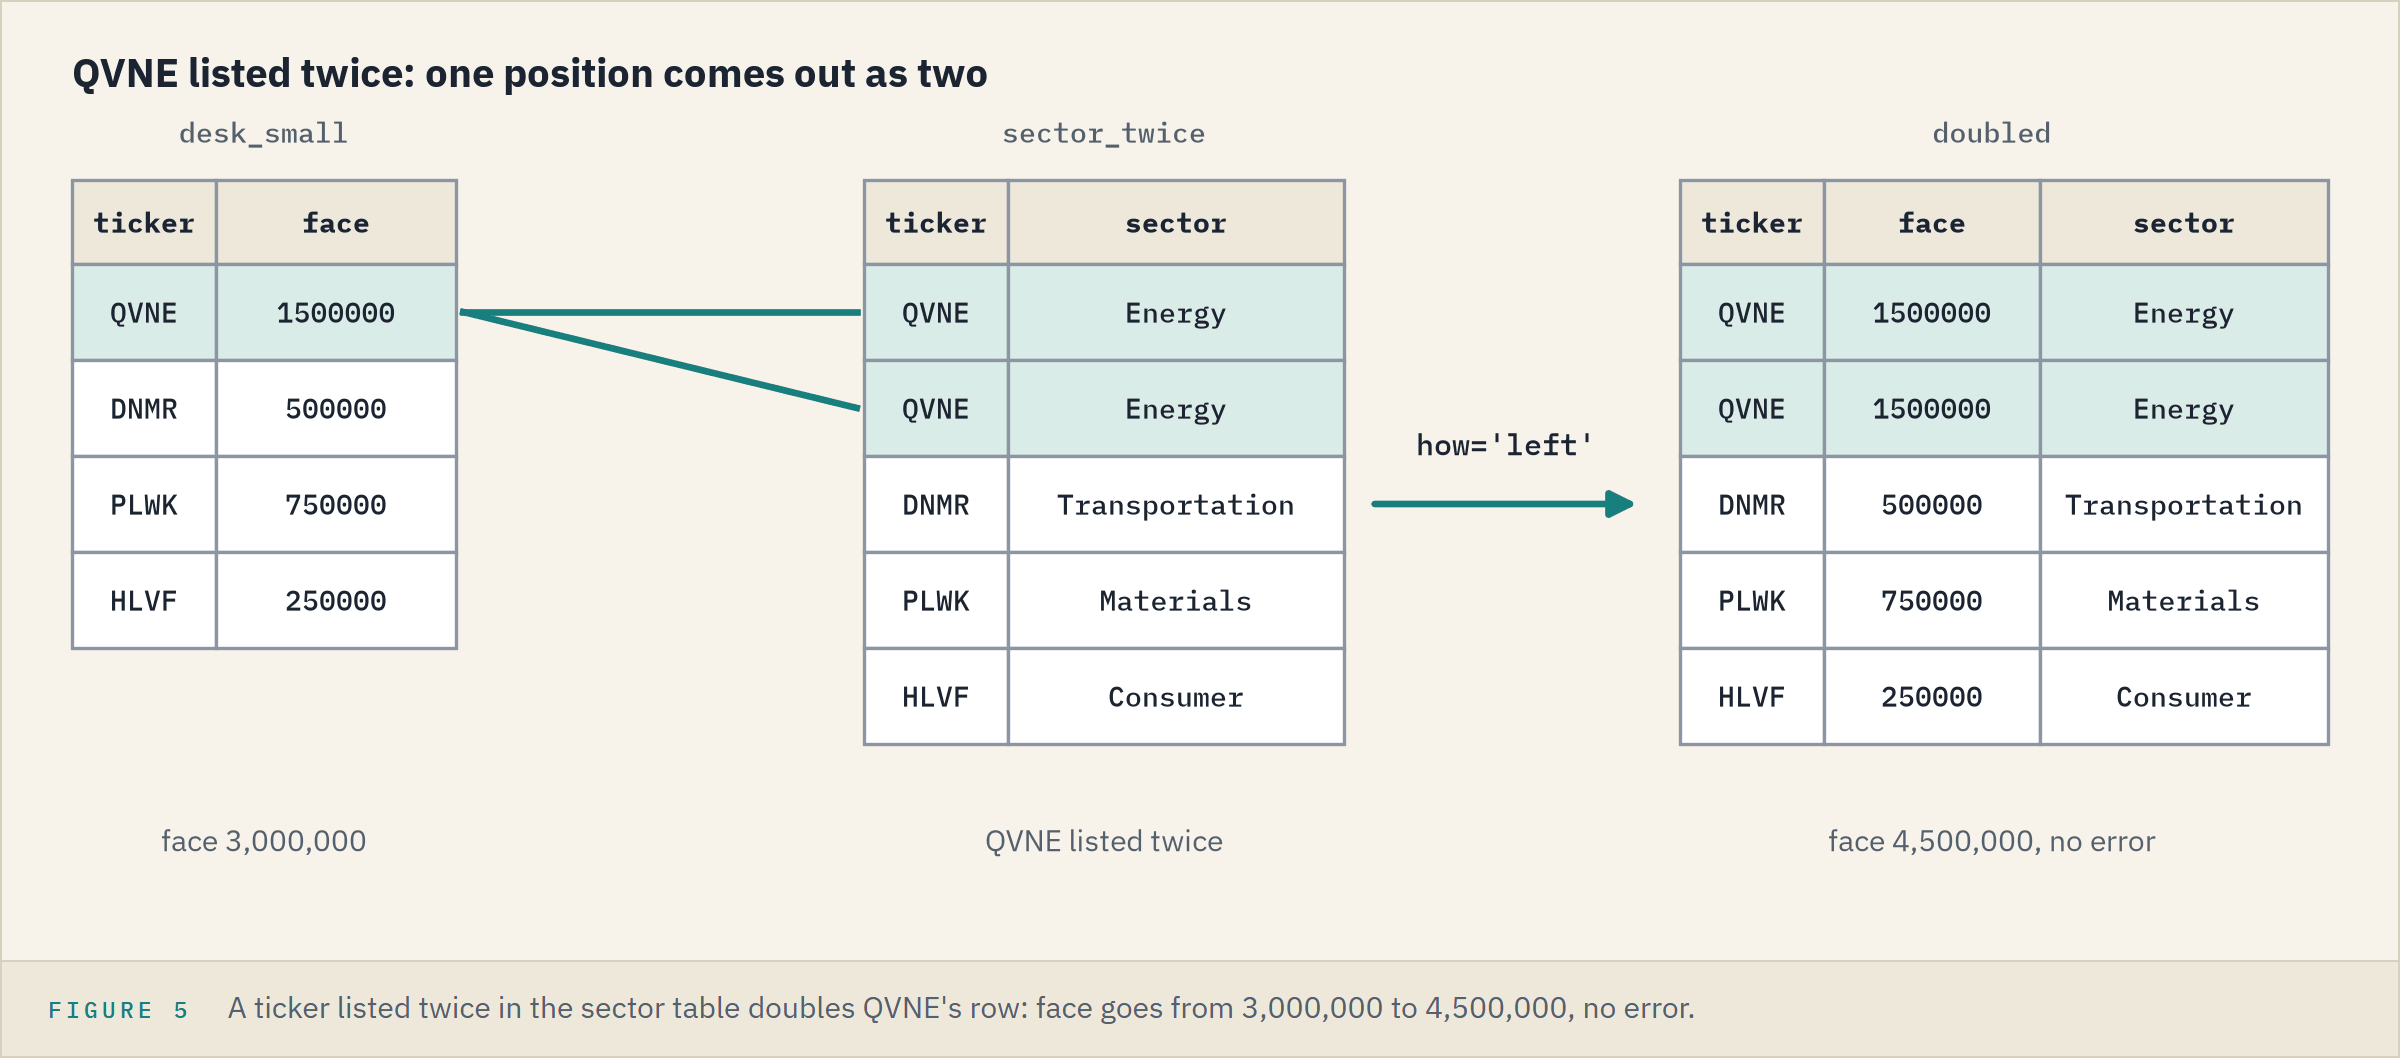

B, and nothing warned: five rows from four is the only sign.
A missing key drops rows, a repeated key repeats them: every total changes.

**Print the row count after every merge.**

### Make `merge` Refuse It

Q. Ask `merge` to refuse a lookup table that lists a key twice.

In [18]:
# many_to_one: many left rows may share a key; the right table lists each key once
pd.merge(desk_small, sector_twice, on='ticker', how='left', validate='many_to_one')

MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 ticker
  QVNE ...

The merge stopped, so nothing was doubled; the wording varies by pandas version.
Every lookup today is many to one: many positions, one row per key.

### The Guard on the Real Files

Q. Guard the real lookup, then check every position found its issuer.

In [19]:
# the issuers list each ticker once, so the guard passes
guarded = pd.merge(positions, issuer_details, on='ticker', how='left',
                   validate='many_to_one')
# assert, as in week 1's Day 3: silent when true
assert guarded.shape[0] == positions.shape[0], 'the merge changed the row count'

In [20]:
# a left merge with the indicator: all 200 positions, marked
matched = pd.merge(positions, issuer_details, on='ticker', how='left', indicator=True)
matched['_merge'].value_counts()

_merge
both          200
left_only       0
right_only      0
Name: count, dtype: int64

Silent: the guard passed, and it runs again on next month's file.
All 200 read `both`, so the inner merge in 8.2 dropped nothing.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">A key with no match</td><td align="left"><code>NaN</code>, found with <code>isna()</code></td><td align="left"><code>#N/A</code>, found with <code>=ISNA(...)</code></td></tr>
<tr><td align="left">Choose the join</td><td align="left"><code>how=</code></td><td align="left">Power Query's Merge Queries (Excel 2016 on): Join Kind Inner, Left Outer, Right Outer, or Full Outer</td></tr>
<tr><td align="left">A key listed twice</td><td align="left">rows repeated; <code>validate=</code> refuses</td><td align="left"><code>VLOOKUP</code> takes the first match; <code>=COUNTIF(A:A, A2)</code> above 1 finds repeats</td></tr>
</table>
<br clear="left">

**`validate=` refuses a repeated key; `isna()` and the `_merge` counts find a missing one.**

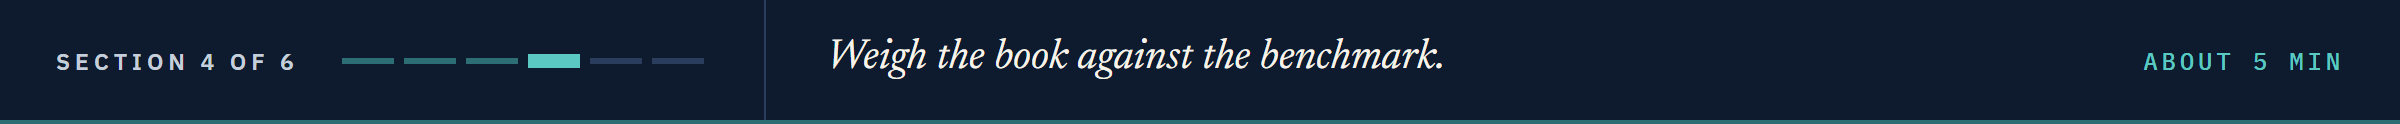

## 8.4 The Portfolio Against the Benchmark

### Load the Holdings and the Benchmark

Both files name a bond by its CUSIP, so the CUSIP is the key.

Q. Load both files. How large is each, and what do the benchmark's weights add up to?

In [21]:
# the desk's holdings and the benchmark, both keyed by CUSIP
holdings = pd.read_csv(data_folder + 'holdings.csv')
benchmark = pd.read_csv(data_folder + 'benchmark.csv')
print(holdings.shape, benchmark.shape)
# weight_pct: each bond's weight in the benchmark, in percent
print('Benchmark weights:', round(benchmark['weight_pct'].sum(), 2))

(200, 19) (821, 19)
Benchmark weights: 100.0


Where the holdings have `par_held`, the benchmark has `weight_pct`.

### Each Benchmark Bond, With the Desk's Face

Q. Mark each benchmark bond with the face the desk holds in it.

In [22]:
# the benchmark on the left keeps all 821; pass only the key and the column wanted
desk_face = holdings[['cusip', 'par_held']]
compared = pd.merge(benchmark, desk_face, on='cusip', how='left')
print(compared.shape)
compared[['cusip', 'ticker', 'weight_pct', 'par_held']].head(4)

(821, 20)


,cusip,ticker,weight_pct,par_held
0,99001BAA4,QVNE,0.2076,2750000.0
1,99001BAB2,QVNE,0.1551,NaN
2,99001BAC0,QVNE,0.0245,NaN
3,99001BAD8,QVNE,0.2024,NaN


### Both Tables Have a `price`

**Predict 5**

Q. Both files have a `price` column besides the key. What does `pd.merge(benchmark[['cusip', 'price']], holdings[['cusip', 'price']], on='cusip')` give?

A) An error: two columns would share one name.
B) One `price` column, from the left table.
C) Two price columns, under new names.

In [23]:
# both tables have a price column, as well as the key
same_name = pd.merge(benchmark[['cusip', 'price']], holdings[['cusip', 'price']], on='cusip')
same_name.head(2)

,cusip,price_x,price_y
0,99001BAA4,98.882,98.882
1,99001BAF3,91.884,91.884


C: `price_x` from the left table, `price_y` from the right.

### Held and Not Held

Q. How many benchmark bonds does the desk hold, and what share of the benchmark's weight do they carry?

In [24]:
# a face means held; NaN means not
held = compared['par_held'].notna()
not_held = compared['par_held'].isna()
print('Held:', held.sum(), 'Not held:', not_held.sum())
print('Weight held:', round(compared.loc[held, 'weight_pct'].sum(), 2))
print('Weight not held:', round(compared.loc[not_held, 'weight_pct'].sum(), 2))

Held: 200 Not held: 621
Weight held: 24.56
Weight not held: 75.44


### Anything Outside the Benchmark?

Q. Does the desk hold any bond the benchmark does not?

In [25]:
# outer keeps every CUSIP from either file
both_files = pd.merge(benchmark, desk_face, on='cusip', how='outer', indicator=True)
both_files['_merge'].value_counts()

_merge
left_only     621
both          200
right_only      0
Name: count, dtype: int64

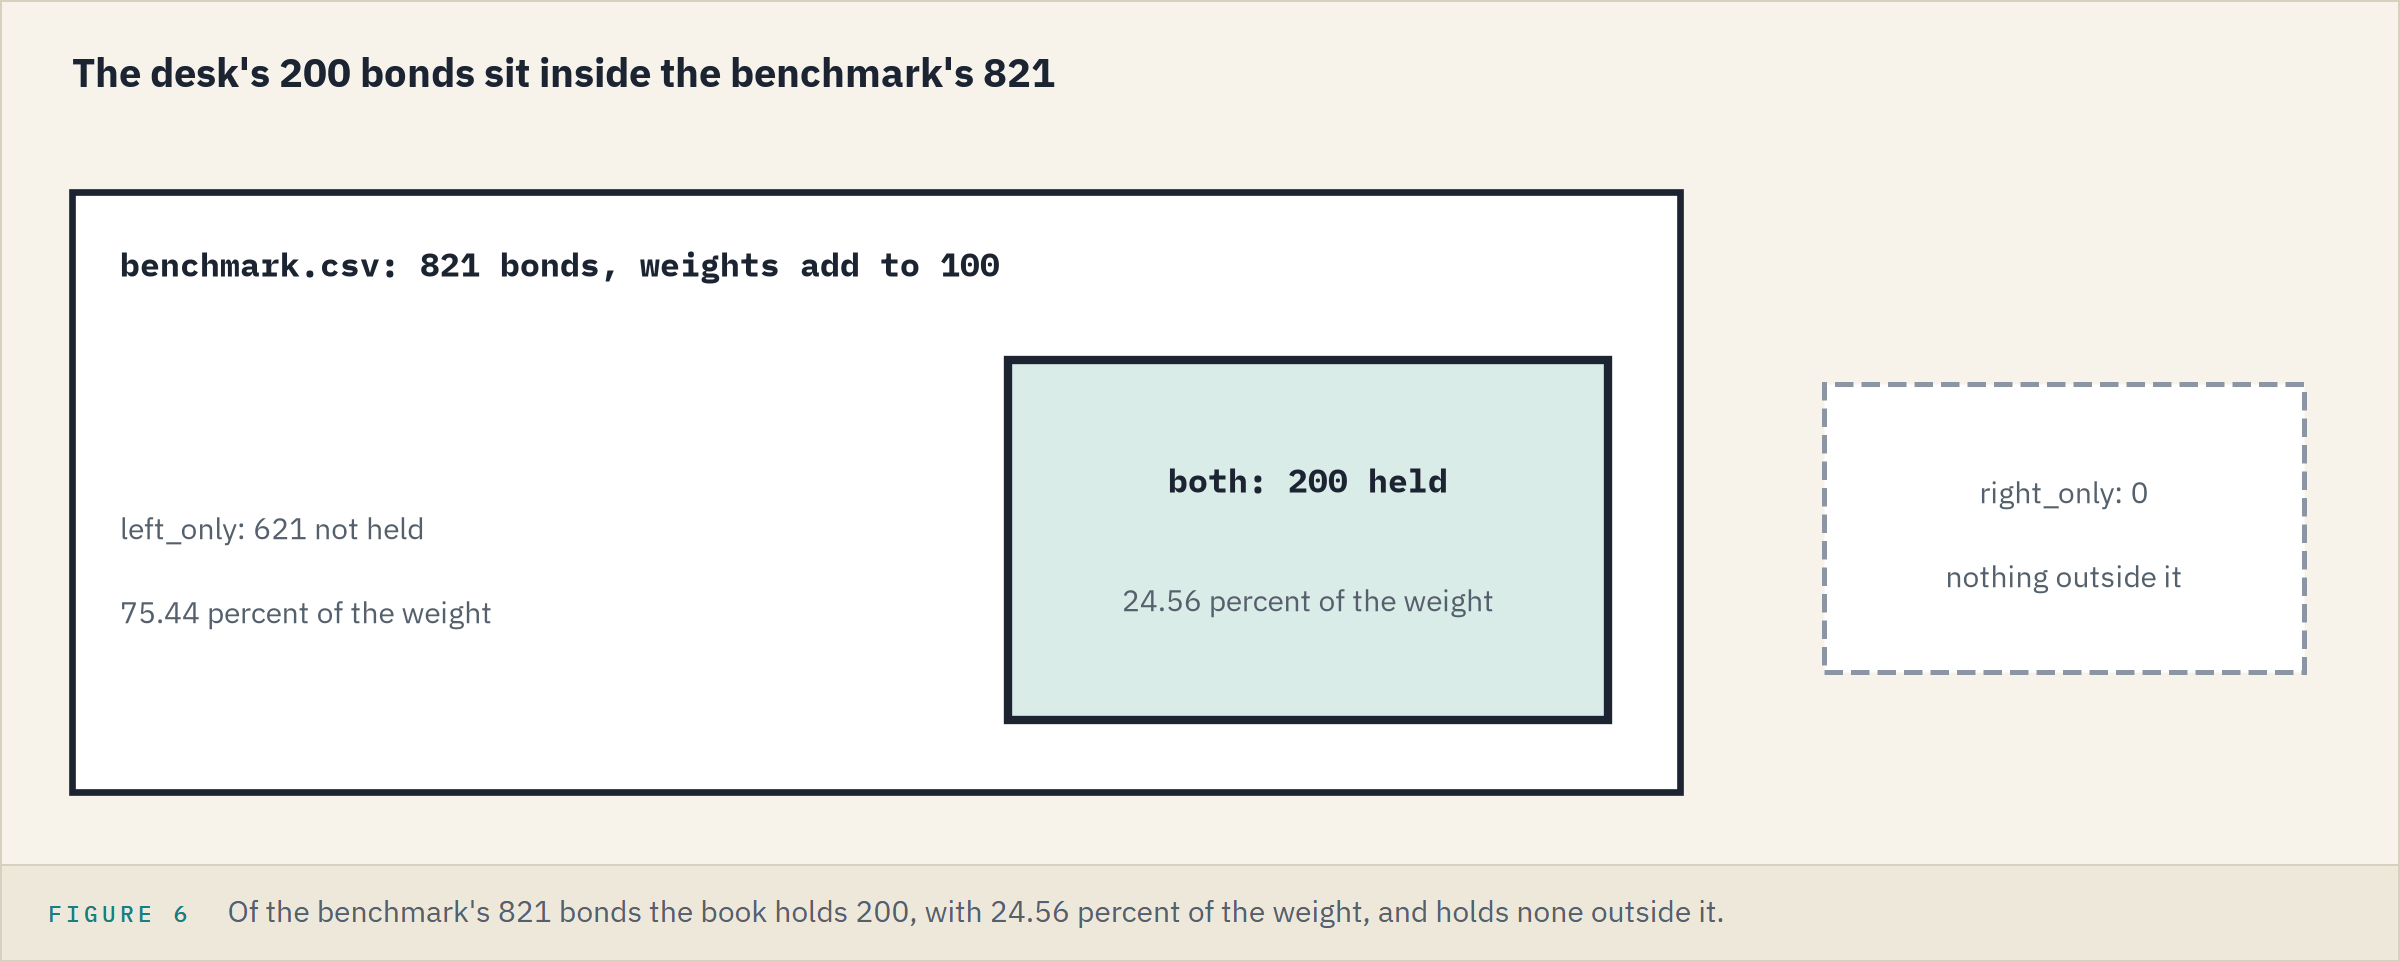

**Excel side by side.** On the benchmark sheet, a helper column T with `=COUNTIF(holdings!B:B, B2)` gives 1 for a bond held and 0 for one not; `=SUMIFS(S:S, T:T, 1)` adds the weights held, column S.

**200 of 821 bonds, 24.56 percent of the weight, nothing outside it.**

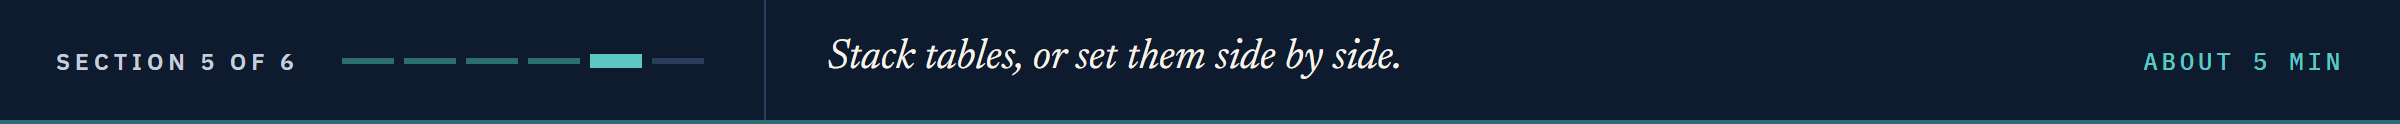

## 8.5 Stacking Tables With `concat`

### The Book: Holdings With the Rating Scale

`merge` matches rows on a key and adds columns; `concat`, by default, adds rows.

Q. Add the score, bucket, and grade to the holdings, and call the result `book`: the table for the rest of the day.

In [26]:
# holdings.csv already carries each bond's rating
book = pd.merge(holdings, ratings, on='rating')
print(book.shape)

(200, 22)


### Two Traders' Tables, Stacked

Q. Investment grade and high yield arrive from two traders. Split the book that way, then stack the two.

In [27]:
# two filters (7.7): the two traders' tables
ig_book = book[book['grade'] == 'Investment Grade']
hy_book = book[book['grade'] == 'High Yield']
# pd.concat() stacks a list of tables, one under the next
stacked = pd.concat([ig_book, hy_book])
print(ig_book.shape, hy_book.shape, stacked.shape)
print('Market value:', stacked['market_value'].sum())

(128, 22) (72, 22) (200, 22)
Market value: 490819215.0


490,819,215, the last notebook's total: nothing lost or repeated.
`concat` lines the columns up by name; a column missing from one table is `NaN` in its rows.

### Labels at the Seam

Q. What row labels sit where the first table ends and the second begins?

In [28]:
# positions 126 to 129: the last two investment grade rows, then the first two high yield
print(stacked.index[126:130].tolist())
# ignore_index=True numbers the rows again from 0
stacked = pd.concat([ig_book, hy_book], ignore_index=True)
print(stacked.index[126:130].tolist())

[198, 199, 1, 2]
[126, 127, 128, 129]


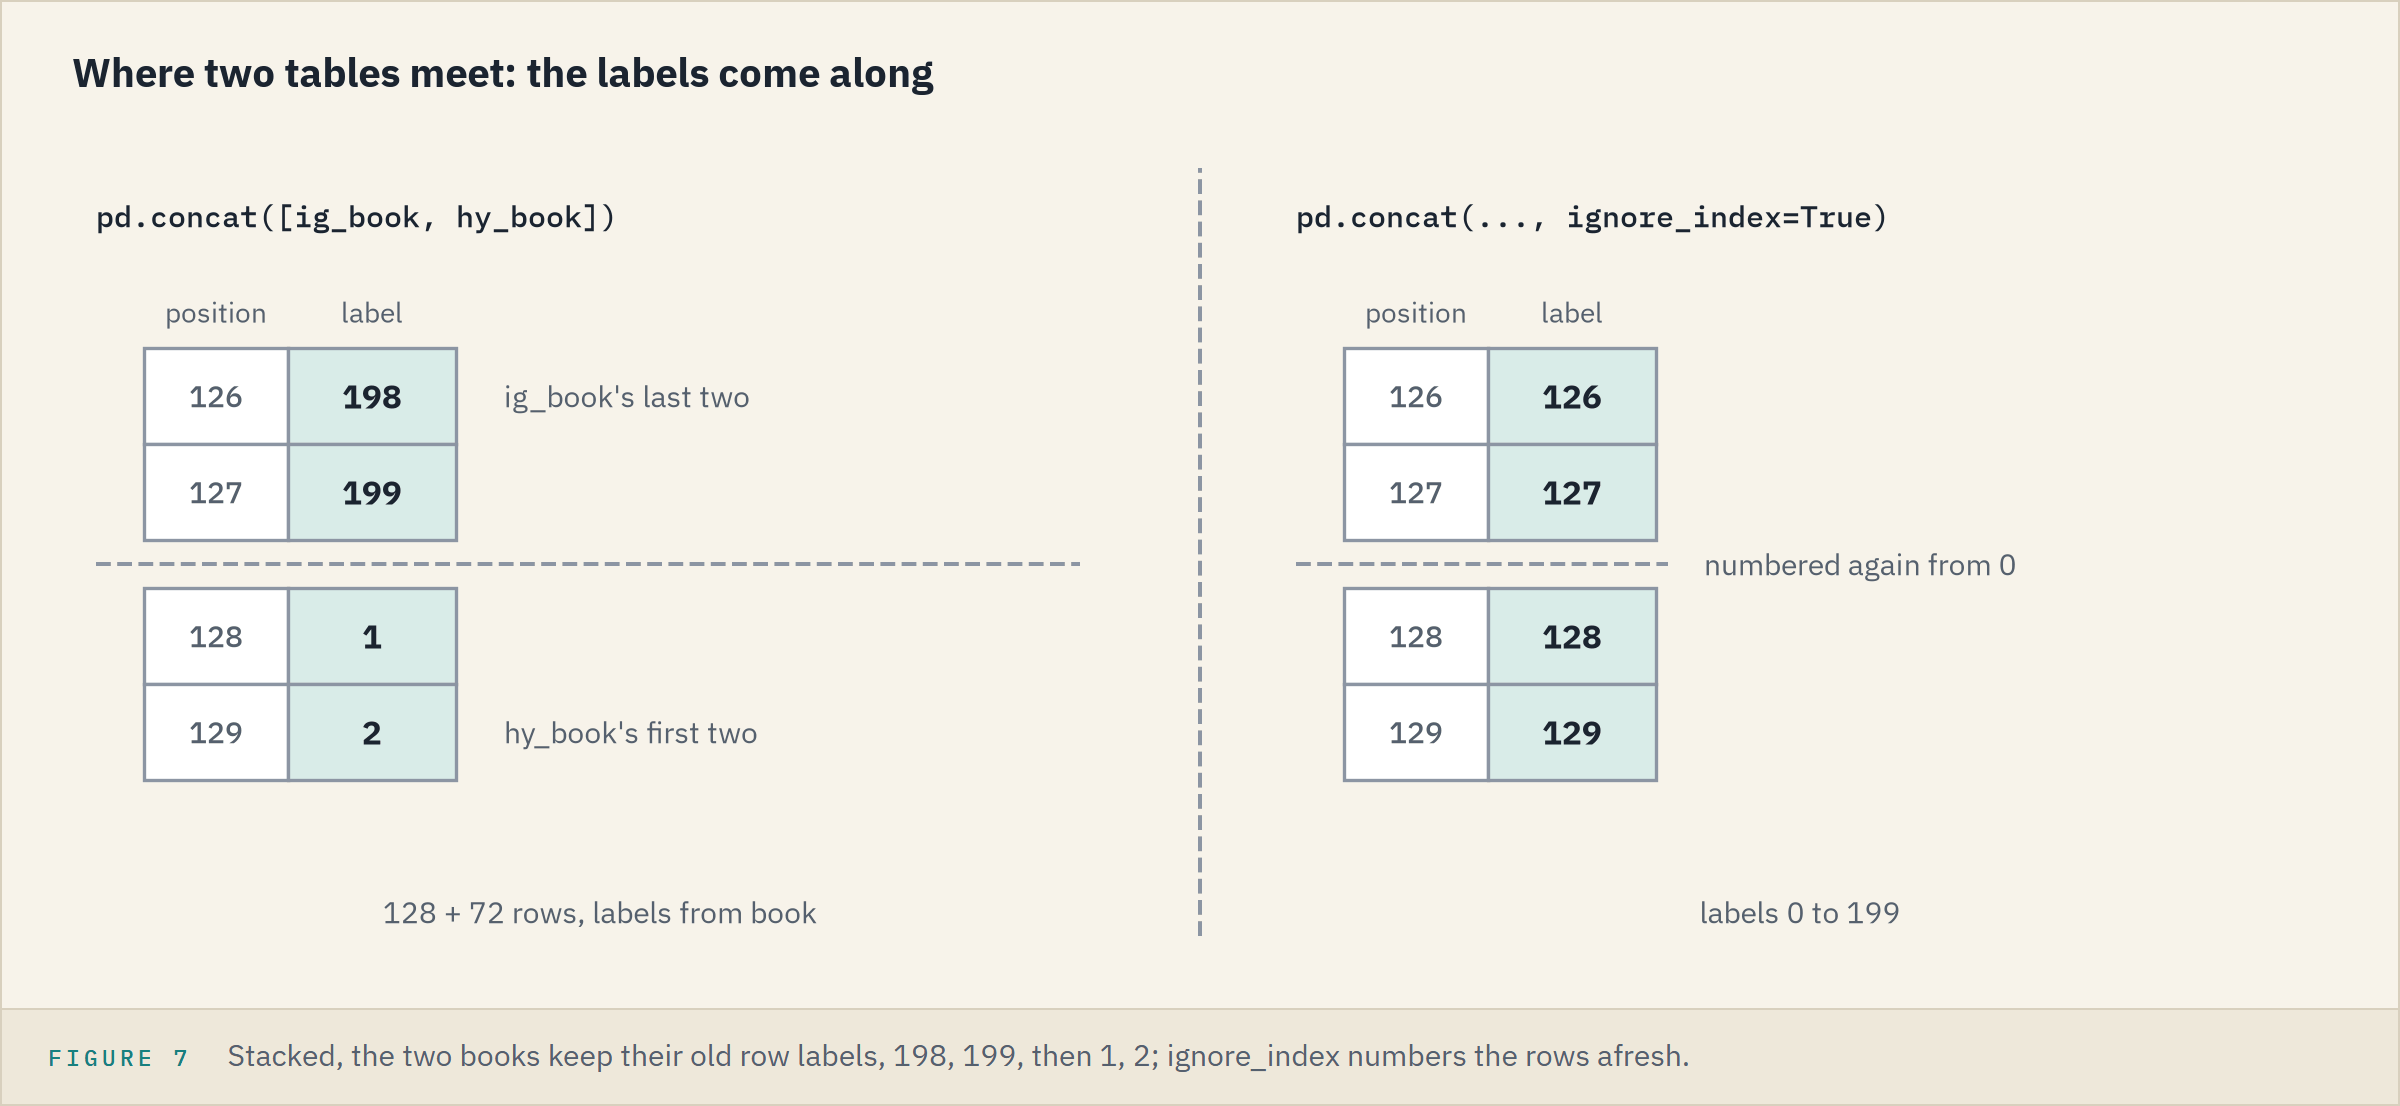

Each row kept its label from `book`, as a filter keeps it (7.7).
Two daily files that each count from 0 would stack with every label twice, and `loc[0]` would return two rows.

### Side by Side With `axis=1`

Q. One system sends the first three prices, another their spreads. Put them side by side, then with spreads for rows 1 to 3.

In [29]:
# three prices from one system, their spreads from another
price_part = book[['ticker', 'price']].head(3)
oas_part = book[['oas']].head(3)
# axis=1 (NumPy 6.7) puts the tables side by side, matched on row labels
print(pd.concat([price_part, oas_part], axis=1))

  ticker    price  oas
0   BEZE  106.727  147
1   BEZH   97.556  535
2   BEZL   98.730  153


In [30]:
# spreads for rows 1 to 3
oas_shifted = book[['oas']].iloc[1:4]
print(pd.concat([price_part, oas_shifted], axis=1))

  ticker    price    oas
0   BEZE  106.727    NaN
1   BEZH   97.556  535.0
2   BEZL   98.730  153.0
3    NaN      NaN  218.0


A label in one table only gets `NaN` in the other's columns.
`axis=0`, the default, stacks.

**Excel side by side.** Pasting one range under another, or `=VSTACK(range1, range2)` in Microsoft 365 and Excel 2024, is `concat`; `=HSTACK(range1, range2)` sets ranges side by side, as `axis=1` does.
Excel lines ranges up by position, so `HSTACK` would set row 1's spread beside row 0's price; pandas lines them up by label.

**A key column: `merge`. Row labels, or one table under another: `concat`.**

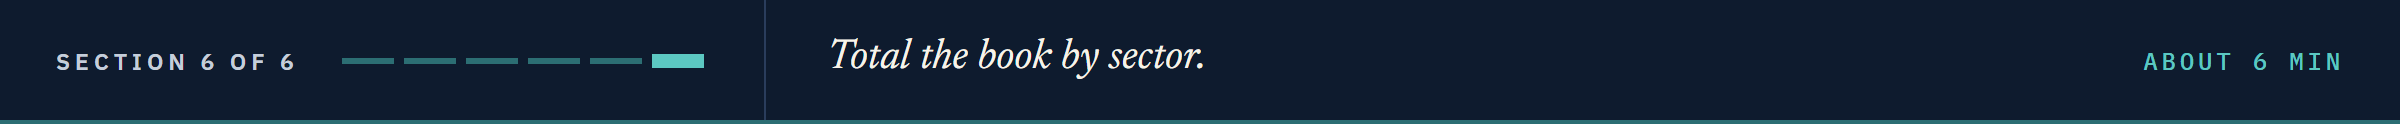

## 8.6 Summarizing by Group

### Market Value by Sector

A list of 200 bonds is not a report: Excel's answer is a PivotTable, pandas' is `groupby`.

Q. What is the book's market value in each sector?

In [31]:
# groupby() splits the rows by sector, ['market_value'] picks the column,
# and sum() adds up each group
sector_value = book.groupby('sector')['market_value'].sum()
sector_value

sector
Consumer          56629597.5
Energy            38830005.0
Financials        68219672.5
Health Care       38908187.5
Industrials       52540745.0
Materials         71701617.5
Technology        30311760.0
Telecom           55848270.0
Transportation    48822897.5
Utilities         29006462.5
Name: market_value, dtype: float64

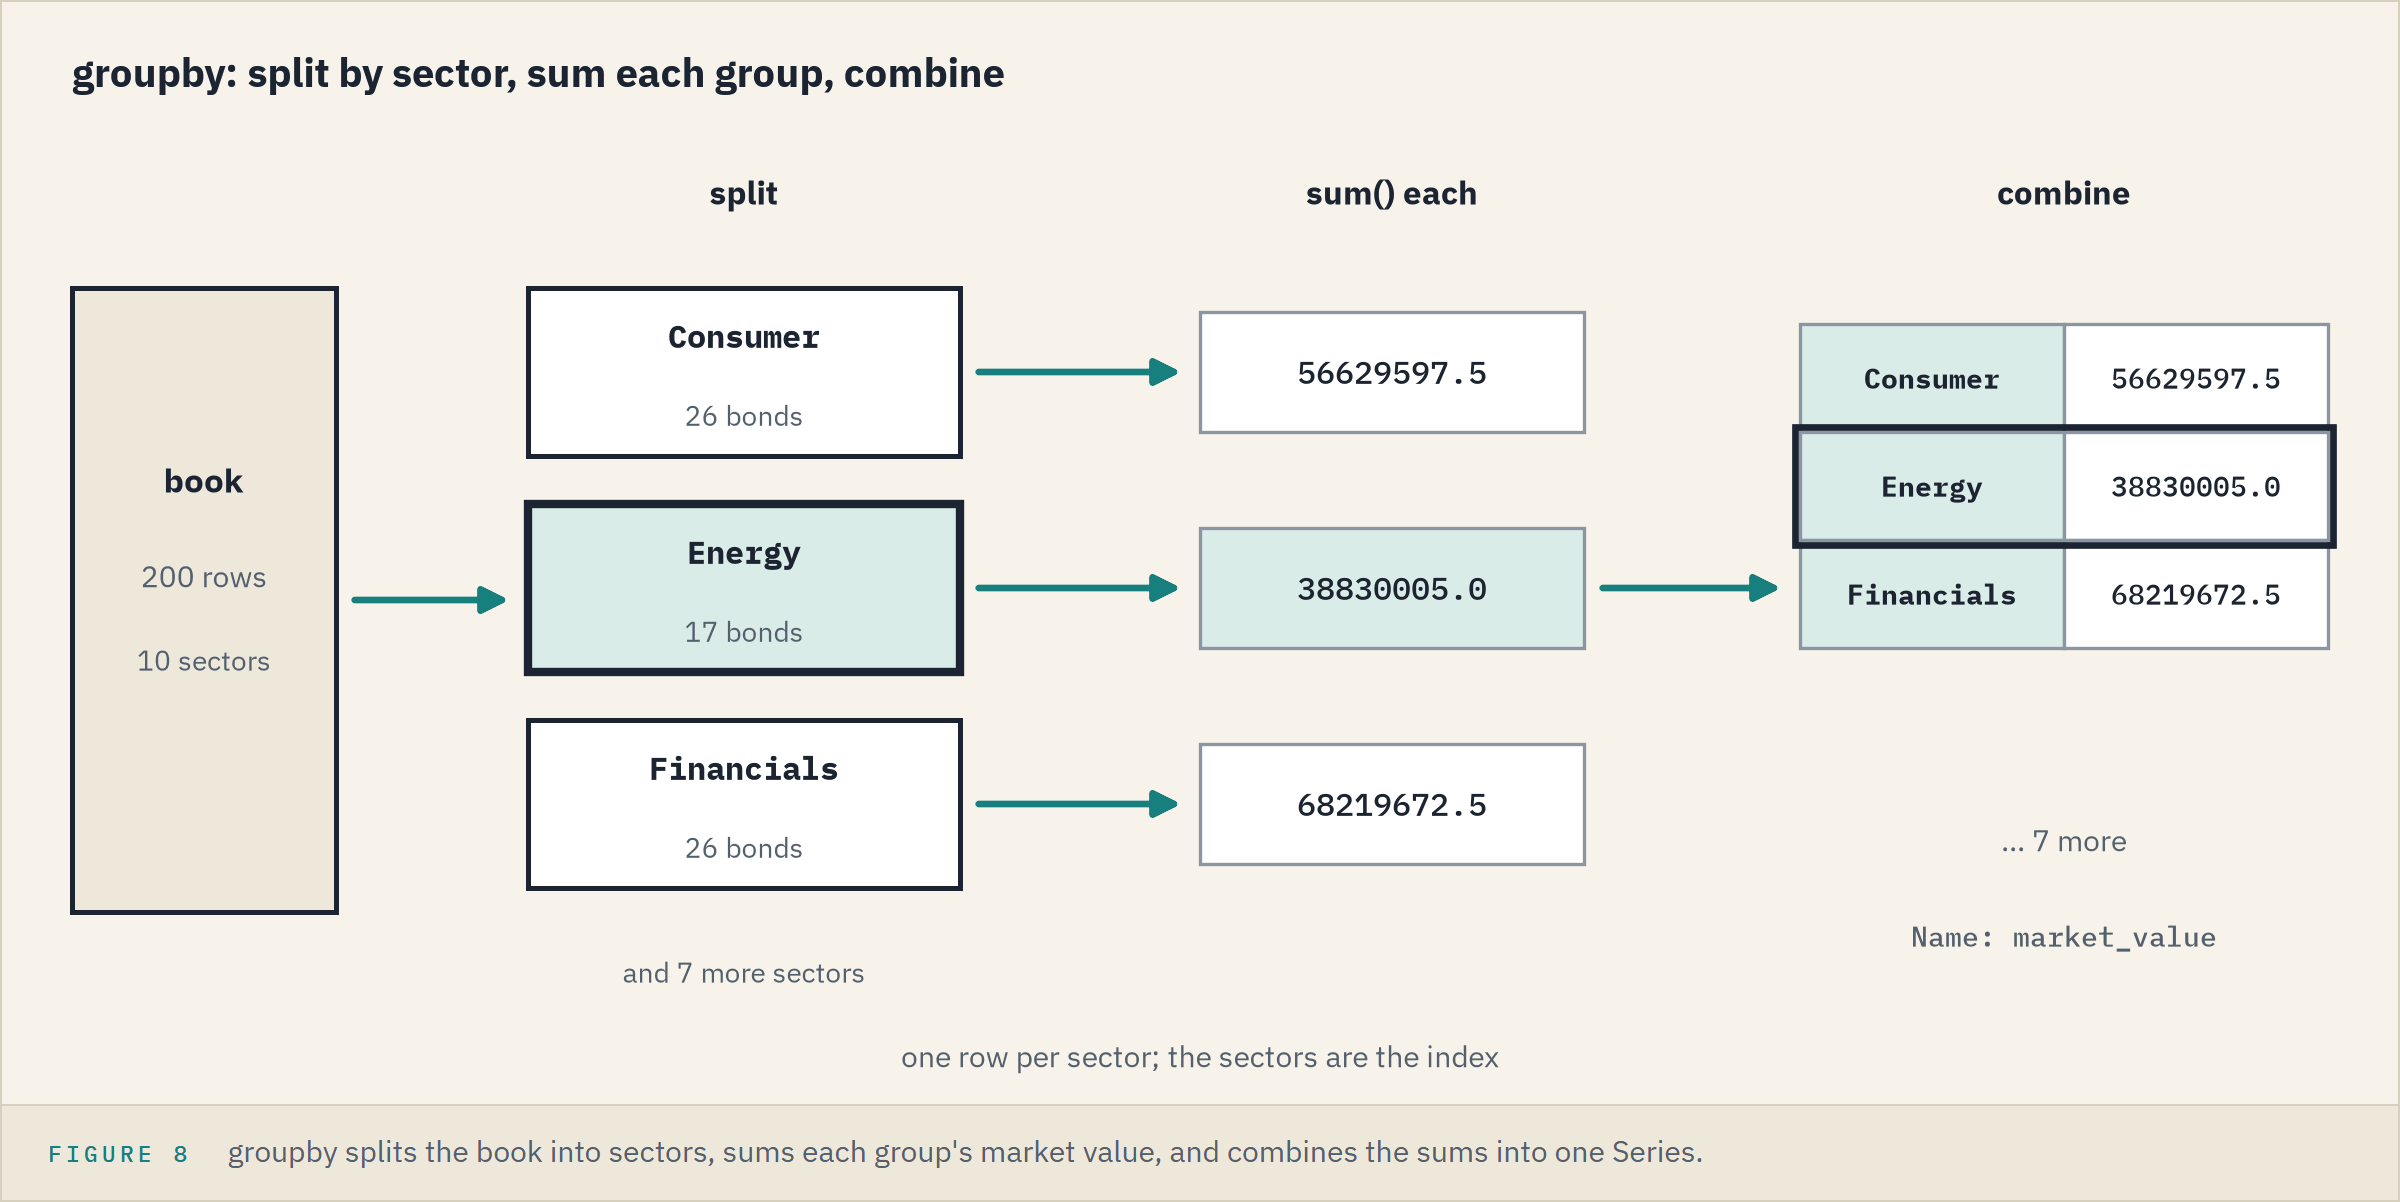

Energy's 38,830,005 is 7.7's filter; any statistic from 7.6 can take the place of `sum()`.
A row whose sector is `NaN` joins no group: it drops out with no warning, as in an inner merge.

**One line does the last notebook's filter for every sector.**

### The Three Largest Sectors

Q. Which three sectors hold the most market value?

In [32]:
# one method straight after another: method chaining, read left to right
top_three = sector_value.sort_values(ascending=False).head(3)
print(top_three)
# the sector names are the index; tolist() as in 7.6
print(top_three.index.tolist())

sector
Materials     71701617.5
Financials    68219672.5
Consumer      56629597.5
Name: market_value, dtype: float64
['Materials', 'Financials', 'Consumer']


The three sectors with 26 bonds each (7.6).

### Average Spread by Rating Bucket

Q. What is the average OAS in each rating bucket, in credit order?

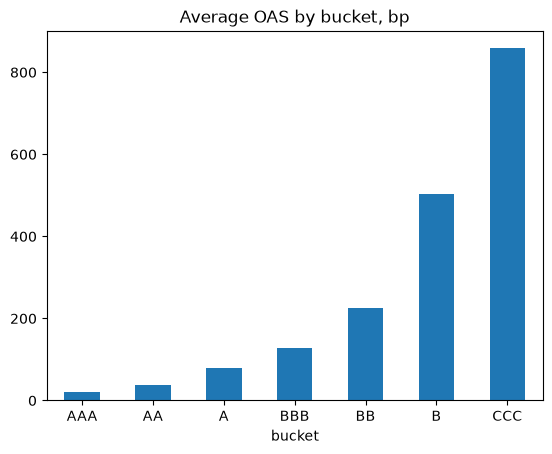

In [33]:
# mean OAS in each bucket, as sum() did per sector
bucket_oas = book.groupby('bucket')['oas'].mean()
# groupby sorts the groups alphabetically; loc with a list puts them in credit order
credit_order = ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC']
chart = bucket_oas.loc[credit_order].plot.bar(rot=0, title='Average OAS by bucket, bp')

Each bucket is wider than the one above it.
A's 79.41 is 7.7's single-A `isin()` figure, now one group of seven.

### Several Statistics per Grade

Q. For each grade, show the number of bonds and the mean, median, lowest, and highest OAS.

In [34]:
# agg() with a list: one column per statistic; round(2) chained on the end
book.groupby('grade')['oas'].agg(['count', 'mean', 'median', 'min', 'max']).round(2)

,count,mean,median,min,max
grade,,,,,
High Yield,72,339.38,250.5,125,1551
Investment Grade,128,99.34,95.0,19,204


High yield's mean sits well above its median: a few very wide bonds pull it up (7.4).

### The Sector Summary

Q. Summarize each sector: the bond count, market value, average OAS, and average duration.

In [35]:
# each line reads: new column name = (column to use, statistic)
sector_summary = book.groupby('sector').agg(
    bonds=('cusip', 'count'),
    market_value=('market_value', 'sum'),
    avg_oas=('oas', 'mean'),
    avg_duration=('duration', 'mean'),
)
sector_summary = sector_summary.round(2)

(sector_summary.style
    .format({'market_value': '{:,.0f}', 'avg_oas': '{:,.2f}', 'avg_duration': '{:,.2f}'})
    .background_gradient(subset=['avg_oas'], cmap='Greens')
    .set_caption('Sector summary'))

,bonds,market_value,avg_oas,avg_duration
sector,,,,
Consumer,26,"56,629,598",218.88,6.84
Energy,17,"38,830,005",171.59,6.97
Financials,26,"68,219,672",172.31,6.15
Health Care,20,"38,908,188",141.75,5.87
Industrials,20,"52,540,745",220.55,6.33
Materials,26,"71,701,618",182.42,5.61
Technology,12,"30,311,760",298.17,5.75
Telecom,21,"55,848,270",182.38,6.35
Transportation,20,"48,822,898",126.50,8.19


The pivot table's twin, styled as in 7.10.
Technology is widest, 298.17 bp on 12 bonds; Transportation is tightest, 126.5, and longest, 8.19 years.

**Excel side by side.** Sector in column E, OAS in M, market value in S, as in `holdings.csv`:

<table align="left">
<tr><th align="left">Question</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Market value of one sector</td><td align="left"><code>sector_value.loc['Energy']</code></td><td align="left"><code>=SUMIFS(S:S, E:E, "Energy")</code></td></tr>
<tr><td align="left">Average OAS of one sector</td><td align="left"><code>book.groupby('sector')['oas'].mean().loc['Energy']</code></td><td align="left"><code>=AVERAGEIFS(M:M, E:E, "Energy")</code></td></tr>
<tr><td align="left">Bonds in one sector</td><td align="left"><code>book.groupby('sector')['cusip'].count().loc['Energy']</code></td><td align="left"><code>=COUNTIFS(E:E, "Energy")</code></td></tr>
<tr><td align="left">Every sector at once</td><td align="left"><code>book.groupby('sector')['market_value'].sum()</code></td><td align="left">a PivotTable: sector in Rows, Sum of market_value in Values</td></tr>
<tr><td align="left">Several statistics at once</td><td align="left"><code>agg(...)</code></td><td align="left">more fields in Values</td></tr>
</table>
<br clear="left">

### The Book Against the Benchmark, by Sector

Q. What share of the book's market value is in each sector, beside the benchmark's weight?

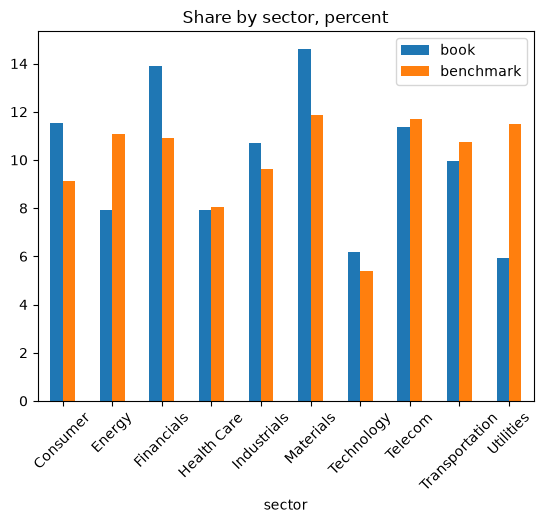

In [36]:
# each sector's share of the book's market value, in percent
book_pct = sector_value / sector_value.sum() * 100
# the benchmark's weights, added up by sector
bench_pct = benchmark.groupby('sector')['weight_pct'].sum()
# a dictionary of Series (7.2) lines the two up by sector
shares = pd.DataFrame({'book': book_pct, 'benchmark': bench_pct})
chart = shares.plot.bar(rot=45, title='Share by sector, percent')

The two largest gaps: Utilities, 5.91 percent of the book against 11.50 of the benchmark, and Energy, 7.91 against 11.06.

**One `groupby` per question: 200 rows became ten sectors beside the benchmark.**

## You Can Now

By the end of this notebook, you can:

* Join positions to issuer details and a rating scale with `merge`, as `VLOOKUP` does, and check the row count
* Choose `inner`, `left`, `right`, or `outer`, and find what did not match with `indicator=True` and `isna()`
* Guard a merge with `validate='many_to_one'` and an `assert`
* Compare a portfolio with its benchmark by CUSIP: bonds held and the weight they carry
* Stack tables with `concat`, and set them side by side with `axis=1`
* Summarize with `groupby` and `agg`, and set the book's share by sector beside the benchmark's

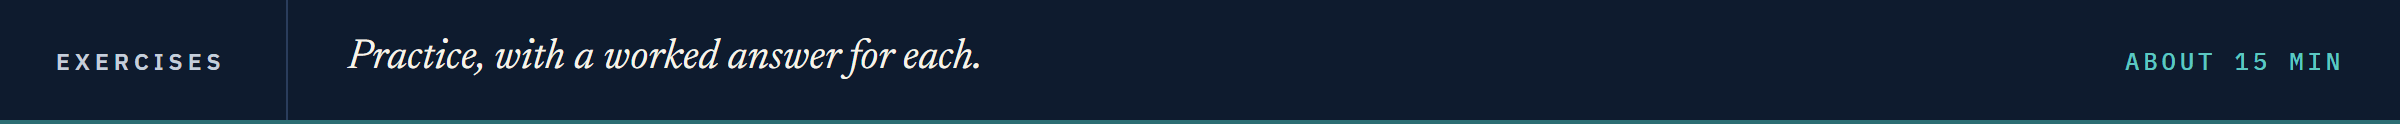

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use the holdings, the benchmark, and the rating scale; the issuers are invented.

Replace each `...` with your own code, then run the check cell under it.
Run the next cell first: it loads fresh copies of the three files and defines `check`, which marks your answers.

In [37]:
import os

import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text;
    # isinstance(expected, list) is True when expected is a list
    if getattr(answer, 'ndim', 0) > 0 and not isinstance(expected, list):
        # a whole column or table was stored where a single value is expected
        print(label + ': not yet. A single value is expected, and you have a column or a table.')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance;
        # abs() drops the sign, so this is the size of the gap between the two
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# fresh copies of three files. In Colab they are read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'

holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
benchmark = pd.read_csv(data_folder + 'benchmark.csv')
print(holdings.shape, ratings.shape, benchmark.shape)

(200, 19) (18, 4) (821, 19)


### Exercise 1

Q. Merge the benchmark with the rating scale. How many benchmark bonds are High Yield, and what is their total weight in the benchmark, in percent, rounded to one decimal place? Store the answers in **ex1_count** and **ex1_weight**.

In [38]:
ex1_count = ...
ex1_weight = ...

In [39]:
check('Exercise 1 count', ex1_count, 281)
check('Exercise 1 weight', ex1_weight, 34.4)

Exercise 1 count: not attempted yet
Exercise 1 weight: not attempted yet


### Exercise 2

Q. Merge the holdings with the rating scale, and total the face held in each rating bucket. How much face does the desk hold in the BBB bucket? Which three buckets have the most face, largest first? Store the answers in **ex2_bbb_face** and, as a list, in **ex2_top_buckets**.

In [40]:
ex2_bbb_face = ...
ex2_top_buckets = ...

In [41]:
check('Exercise 2 BBB face', ex2_bbb_face, 151750000)
check('Exercise 2 top buckets', ex2_top_buckets, ['BBB', 'A', 'BB'])

Exercise 2 BBB face: not attempted yet
Exercise 2 top buckets: not attempted yet


### Exercise 3

Q. Mark each benchmark bond with the face the desk holds in it, with a left merge on the CUSIP. Among the benchmark's Energy bonds, how many does the desk hold, and what is their benchmark weight, in percent, rounded to two decimal places? Store the answers in **ex3_count** and **ex3_weight**.

In [42]:
ex3_count = ...
ex3_weight = ...

In [43]:
check('Exercise 3 count', ex3_count, 17)
check('Exercise 3 weight', ex3_weight, 2.29)

Exercise 3 count: not attempted yet
Exercise 3 weight: not attempted yet


### Exercise 4

Q. Split the holdings into the bonds priced below 100 and the bonds priced at 100 or above. Store the number of bonds below 100 in **ex4_below**. Stack the two tables with `pd.concat()`, numbering the rows again from 0, and store the result in **ex4_stacked**. Then store its number of rows in **ex4_rows** and its total market value in **ex4_value**.

In [44]:
ex4_below = ...
ex4_stacked = ...
ex4_rows = ...
ex4_value = ...

In [45]:
check('Exercise 4 below 100', ex4_below, 113)
check('Exercise 4 rows', ex4_rows, 200)
check('Exercise 4 market value', ex4_value, 490819215.0)

Exercise 4 below 100: not attempted yet
Exercise 4 rows: not attempted yet
Exercise 4 market value: not attempted yet


### Exercise 5: AI check

You ask an AI assistant how many of the benchmark's Energy bonds the desk holds, and what benchmark weight they carry.
It gives you the code below.
It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. What numbers do you expect? You worked both out yourself in Exercise 3. Then run the code. Does it agree with you?

In [46]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
ai_desk = holdings[['ticker', 'par_held']]
ai_compared = pd.merge(benchmark, ai_desk, on='ticker', how='left')

ai_held = ai_compared['par_held'].notna() & (ai_compared['sector'] == 'Energy')
ex5_count = ai_held.sum()
ex5_weight = round(ai_compared.loc[ai_held, 'weight_pct'].sum(), 2)

print(f'Energy bonds held: {ex5_count}')
print(f'Their benchmark weight: {ex5_weight}')

Energy bonds held: 96
Their benchmark weight: 12.2


Q. Find the bug and fix the code in the cell above, so that **ex5_count** and **ex5_weight** hold the right answers.

In [47]:
check('Exercise 5 count', ex5_count, 17)
check('Exercise 5 weight', ex5_weight, 2.29)

Exercise 5 count: not yet. You have 96
Exercise 5 weight: not yet. You have 12.2


## Congratulations!

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">A name, sector, and rating on every position</td><td align="left">three files, two keys: 200 in, 200 out</td></tr>
<tr><td align="left">None lost or doubled</td><td align="left"><code>validate=</code>, an <code>assert</code>, and all 200 <code>both</code></td></tr>
<tr><td align="left">Benchmark bonds held, and their weight</td><td align="left">200 of 821, 24.56 percent of the weight</td></tr>
<tr><td align="left">The book by sector, in money, beside the benchmark</td><td align="left"><code>groupby</code>, and the share chart</td></tr>
</table>
<br clear="left">

Be proud: a `VLOOKUP`, a stack, and a pivot table are now lines of code that run again on next month's files.

Every average today counted each bond once.
Part 2 weights them by market value, saves the book to a file and a workbook, and turns its maturity dates into a profile.

[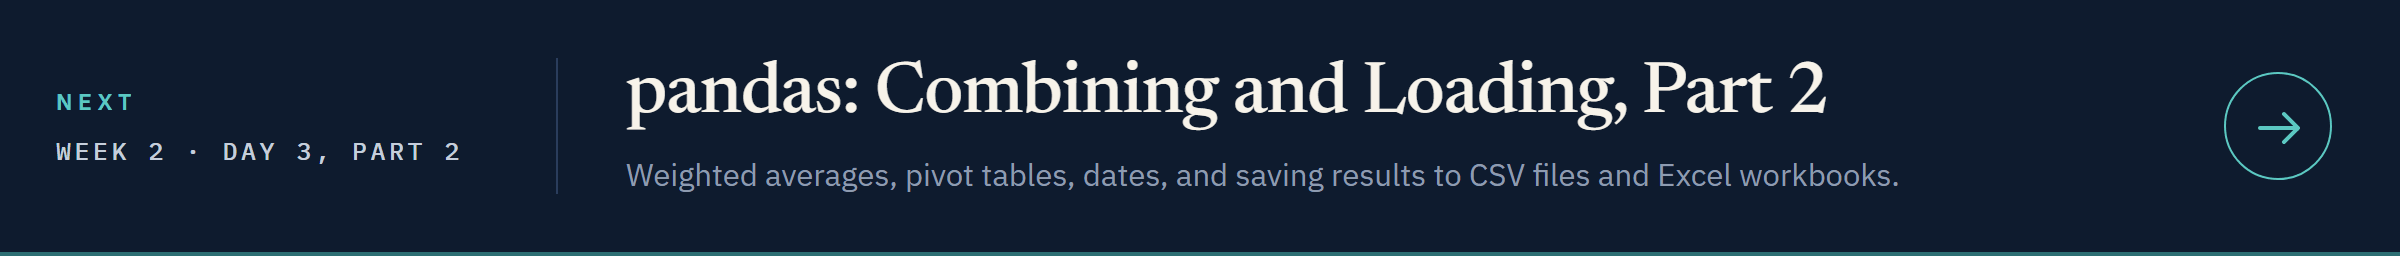](../day3_part2/08_part2_pandas_combining_and_loading.ipynb)

[Open Day 3, Part 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day3_part2/08_part2_pandas_combining_and_loading.ipynb)